# Cognitive Aging — NHANES 2011–2012
**Author:** Claudio Lombardi

This project examines associations of age and education with delayed verbal recall, and explores learning, verbal fluency and digit-symbol performance. It uses public NHANES 2011–2012 data and a cross-sectional design; it does not measure within-person change, establish causal effects or provide diagnoses.

The notebook first describes data quality and unweighted observations, then uses MEC weights and survey design variables for weighted estimates and regression. Comparisons of manual and package calculations use the same data and assumptions; they are not a validation using independent software.

Run all cells in order in Google Colab. The notebook downloads the original public SAS transport files into `data/raw/`; this runtime storage is temporary. It installs `pyreadstat` if necessary and uses `svy` version **0.36.0**, the version checked during development.

Sources: [Cognitive Functioning](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/CFQ_G.htm), [Demographics](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/DEMO_G.htm), [NCHS Data User Agreement](https://www.cdc.gov/nchs/policy/data-user-agreement.html). Use these data only for statistical analysis and reporting, and do not attempt to identify participants or link to identifiable information.


## Project overview and key findings

This project examines how age and education are associated with delayed verbal recall among adults aged 60 and over in the **NHANES 2011–2012** data. Recorded sex is included as an additional model variable.

The primary survey-weighted model included **1,452 participants** with complete data. It accounted for NHANES examination weights, strata and primary sampling units.

- Participants aged **80 and over** had an estimated mean delayed-recall score **2.20 points lower** than those aged 60–69, holding education and recorded sex constant. The 95% confidence interval was **−2.87 to −1.53**.
- College graduates had an estimated mean score **1.42 points higher** than participants with less than 9th-grade education, holding age group and recorded sex constant. The 95% confidence interval was **0.62 to 2.21**.
- A post hoc analysis restricted to the **1,359 participants** included in all four cognitive models produced associations in the same direction.

The project also explores CERAD learning, Animal Fluency and Digit Symbol Substitution Test scores. These secondary outcomes use different scales and, in the main analyses, partially different groups of participants.

**Interpretation:** The findings describe associations, not causal effects or diagnoses. Cognitive scores were missing more often in some age and education groups; survey weights do not automatically eliminate possible bias from missing scores. Several outcomes and comparisons were examined without a multiple-comparison adjustment.

## 1. Import libraries
Python libraries are used to download, inspect and analyze the data.
The SAS transport files are read with `pyreadstat`.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
from urllib.request import urlopen

import pandas as pd
from IPython.display import display

print("Python:", platform.python_version())
print("Pandas:", pd.__version__)


Python: 3.13.18
Pandas: 2.2.3


### Import validation

An initial comparison found that the Pandas XPORT reader represented
some zero values as very small positive numbers. The source files are
therefore imported with `pyreadstat`. The affected data checks and
descriptive tables were rerun after the import was corrected.

## 2. Download the official source files
The download checks reject HTML error pages. A manifest records source URLs, download time and checksums.

In [ ]:
raw_dir = Path("data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)

sources = {
    "CFQ_G": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/CFQ_G.xpt",
    "DEMO_G": "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2011/DataFiles/DEMO_G.xpt",
}

manifest = []
for name, url in sources.items():
    with urlopen(url, timeout=90) as response:
        content = response.read()
    if not content.startswith(b"HEADER RECORD*******LIBRARY HEADER RECORD!!!!!!!"):
        raise ValueError(f"{name}: the response is not an expected SAS transport file.")
    path = raw_dir / f"{name}.xpt"
    path.write_bytes(content)
    manifest.append({
        "file": path.name,
        "source_url": url,
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
        "bytes": len(content),
        "sha256": hashlib.sha256(content).hexdigest(),
    })

(raw_dir / "download_manifest.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8"
)
display(pd.DataFrame(manifest)[["file", "bytes", "downloaded_at_utc"]])


,file,bytes,downloaded_at_utc
0,CFQ_G.xpt,259920,2026-10-30T23:10:50.149736+00:00
1,DEMO_G.xpt,3753760,2026-10-30T23:10:50.330373+00:00


## 3. Read the two tables
`cfq_raw` contains cognitive data and administration status. `demo_raw` contains demographics and survey design variables.

In [ ]:
# Read the original SAS XPORT files using pyreadstat.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("pyreadstat") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "pyreadstat"
    ])

import pyreadstat

cfq_raw, cfq_metadata = pyreadstat.read_xport(
    str(raw_dir / "CFQ_G.xpt")
)

demo_raw, demo_metadata = pyreadstat.read_xport(
    str(raw_dir / "DEMO_G.xpt")
)

overview = pd.DataFrame([
    {
        "dataset": "CFQ_G",
        "rows": len(cfq_raw),
        "columns": cfq_raw.shape[1],
    },
    {
        "dataset": "DEMO_G",
        "rows": len(demo_raw),
        "columns": demo_raw.shape[1],
    },
])

display(overview)

print("Delayed recall scores equal to zero:",
      int((cfq_raw["CFDCSR"] == 0).sum()))
print("Demographic records with MEC weight equal to zero:",
      int((demo_raw["WTMEC2YR"] == 0).sum()))

,dataset,rows,columns
0,CFQ_G,1687,19
1,DEMO_G,9756,48


Delayed recall scores equal to zero: 70
Demographic records with MEC weight equal to zero: 418


## 4. Check identifiers and planned variables
`SEQN` links the files. Each table should have one row per participant. These checks do not imply that all participants completed every test.

In [ ]:
required_cfq = [
    "SEQN", "CFDCSR", "CFDCST1", "CFDCST2", "CFDCST3", "CFDAST", "CFDDS",
    "CFASTAT", "CFDCCS", "CFDCRNC", "CFDAPP", "CFDARNC", "CFDDPP", "CFDDRNC", "CFALANG",
]
required_demo = [
    "SEQN", "RIDAGEYR", "DMDEDUC2", "RIAGENDR", "RIDSTATR",
    "WTMEC2YR", "SDMVSTRA", "SDMVPSU",
]

for name, table, required in [
    ("CFQ_G", cfq_raw, required_cfq),
    ("DEMO_G", demo_raw, required_demo),
]:
    missing_columns = sorted(set(required) - set(table.columns))
    assert not missing_columns, f"{name}: missing columns {missing_columns}"
    assert table["SEQN"].notna().all(), f"{name}: missing participant identifiers"
    assert table["SEQN"].is_unique, f"{name}: duplicate participant identifiers"
    print(f"{name}: identifier and column checks passed.")

unmatched = ~cfq_raw["SEQN"].isin(demo_raw["SEQN"])
assert not unmatched.any(), "Some cognitive records have no demographic match."
print("All cognitive identifiers are present in the demographics table.")

CFQ_G: identifier and column checks passed.
DEMO_G: identifier and column checks passed.
All cognitive identifiers are present in the demographics table.


## 5. Inspect the imported data
SAS numeric fields may appear as decimals; this does not automatically indicate an error. Codes must be interpreted using the official codebooks.

In [ ]:
print("Cognitive data — first five rows:")
display(cfq_raw[required_cfq].head())
print("Demographics — first five rows:")
display(demo_raw[required_demo].head())

scores = ["CFDCST1", "CFDCST2", "CFDCST3", "CFDCSR", "CFDAST", "CFDDS"]
availability = pd.DataFrame({
    "available_scores": cfq_raw[scores].notna().sum(),
    "missing_scores": cfq_raw[scores].isna().sum(),
})
display(availability.rename_axis("variable"))


Cognitive data — first five rows:


,SEQN,CFDCSR,CFDCST1,CFDCST2,CFDCST3,CFDAST,CFDDS,CFASTAT,CFDCCS,CFDCRNC,CFDAPP,CFDARNC,CFDDPP,CFDDRNC,CFALANG
0,62174.0,5.0,3.0,6.0,7.0,18.0,33.0,1.0,1.0,NaN,1.0,NaN,1.0,NaN,1.0
1,62178.0,3.0,3.0,5.0,5.0,12.0,38.0,1.0,1.0,NaN,1.0,NaN,1.0,NaN,1.0
2,62191.0,5.0,4.0,5.0,7.0,17.0,26.0,1.0,1.0,NaN,1.0,NaN,1.0,NaN,1.0
3,62209.0,3.0,3.0,3.0,5.0,15.0,NaN,1.0,1.0,NaN,1.0,NaN,2.0,NaN,2.0
4,62215.0,7.0,5.0,8.0,8.0,15.0,47.0,1.0,1.0,NaN,1.0,NaN,1.0,NaN,1.0


Demographics — first five rows:


,SEQN,RIDAGEYR,DMDEDUC2,RIAGENDR,RIDSTATR,WTMEC2YR,SDMVSTRA,SDMVPSU
0,62161.0,22.0,3.0,1.0,2.0,104236.582554,91.0,1.0
1,62162.0,3.0,NaN,2.0,2.0,16116.354010,92.0,3.0
2,62163.0,14.0,NaN,1.0,2.0,7869.485117,90.0,3.0
3,62164.0,44.0,4.0,2.0,2.0,127965.226204,94.0,1.0
4,62165.0,14.0,NaN,2.0,2.0,13384.042162,90.0,2.0


,available_scores,missing_scores
variable,,
CFDCST1,1467,220
CFDCST2,1463,224
CFDCST3,1458,229
CFDCSR,1454,233
CFDAST,1449,238
CFDDS,1422,265


### Data preparation principles
- A missing test score is not a score of zero.
- Administration status and missingness are examined before determining analytic samples.
- The public age value 80 represents **80 years or older**.
- Survey-adjusted analyses use MEC weights, strata, primary sampling units and subgroup indicators while preserving the full MEC design.


## 6. Participants and data linkage
Define the examined MEC group and verify participant identifiers before merging.


In [ ]:
# Count older participants and their MEC examination status.
age_60_plus = demo_raw["RIDAGEYR"] >= 60
mec_examined = demo_raw["RIDSTATR"] == 2

participant_counts = pd.DataFrame({
    "group": [
        "All participants in the demographics file",
        "Participants aged 60 or older",
        "Participants aged 60 or older examined at MEC",
        "Participants aged 60 or older not examined at MEC",
    ],
    "participants": [
        len(demo_raw),
        int(age_60_plus.sum()),
        int((age_60_plus & mec_examined).sum()),
        int((age_60_plus & ~mec_examined).sum()),
    ],
})

display(participant_counts)

,group,participants
0,All participants in the demographics file,9756
1,Participants aged 60 or older,1791
2,Participants aged 60 or older examined at MEC,1687
3,Participants aged 60 or older not examined at MEC,104


In [ ]:
# Verify that both groups contain exactly the same participants.
older_mec_ids = set(
    demo_raw.loc[age_60_plus & mec_examined, "SEQN"]
)

cognitive_ids = set(cfq_raw["SEQN"])

identity_check = pd.DataFrame({
    "check": [
        "Older MEC participants absent from the cognitive file",
        "Cognitive records outside the older MEC group",
    ],
    "participants": [
        len(older_mec_ids - cognitive_ids),
        len(cognitive_ids - older_mec_ids),
    ],
})

display(identity_check)

assert older_mec_ids == cognitive_ids, (
    "The participant groups do not match. Investigate before merging."
)

print("Verified: both groups contain exactly the same participants.")

,check,participants
0,Older MEC participants absent from the cogniti...,0
1,Cognitive records outside the older MEC group,0


Verified: both groups contain exactly the same participants.


In [ ]:
# Rebuild the merged table using the corrected imports.
for name, table in [("CFQ_G", cfq_raw), ("DEMO_G", demo_raw)]:
    assert table["SEQN"].notna().all(), (
        f"{name}: missing participant identifiers."
    )
    assert table["SEQN"].is_unique, (
        f"{name}: duplicate participant identifiers."
    )

nhanes_raw = demo_raw.merge(
    cfq_raw,
    on="SEQN",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify that cognitive records match the older MEC group.
older_mec_ids = set(
    demo_raw.loc[
        (demo_raw["RIDAGEYR"] >= 60)
        & (demo_raw["RIDSTATR"] == 2),
        "SEQN"
    ]
)

cognitive_ids = set(cfq_raw["SEQN"])

assert older_mec_ids == cognitive_ids, (
    "The older MEC group and cognitive records do not match."
)

merge_check = pd.DataFrame({
    "group": [
        "All rows in the merged table",
        "Participants with a cognitive record",
        "Participants without a cognitive record",
    ],
    "participants": [
        len(nhanes_raw),
        int((nhanes_raw["_merge"] == "both").sum()),
        int((nhanes_raw["_merge"] == "left_only").sum()),
    ],
})

display(merge_check)
print("Identifier checks passed.")

,group,participants
0,All rows in the merged table,9756
1,Participants with a cognitive record,1687
2,Participants without a cognitive record,8069


Identifier checks passed.


In [ ]:
# Check MEC examination status and sample weight availability.
weight_status = pd.Series(
    "Missing",
    index=demo_raw.index
)

weight_status.loc[demo_raw["WTMEC2YR"] == 0] = "Zero"
weight_status.loc[demo_raw["WTMEC2YR"] > 0] = "Positive"
weight_status.loc[demo_raw["WTMEC2YR"] < 0] = "Negative"

weight_check = pd.crosstab(
    demo_raw["RIDSTATR"],
    weight_status,
    rownames=["Interview / MEC status"],
    colnames=["MEC weight status"],
    margins=True,
    margins_name="Total"
)

display(weight_check)

MEC weight status,Positive,Zero,Total
Interview / MEC status,,,
1.0,0,418,418
2.0,9338,0,9338
Total,9338,418,9756


In [ ]:
# Check survey design variables for the older MEC group.
older_mec_check = nhanes_raw.loc[
    (nhanes_raw["RIDAGEYR"] >= 60)
    & (nhanes_raw["RIDSTATR"] == 2)
]

design_check = pd.DataFrame({
    "check": [
        "Participants aged 60+ examined at MEC",
        "Participants with a positive MEC weight",
        "Missing MEC weights",
        "Missing survey strata",
        "Missing primary sampling units",
    ],
    "participants": [
        len(older_mec_check),
        int((older_mec_check["WTMEC2YR"] > 0).sum()),
        int(older_mec_check["WTMEC2YR"].isna().sum()),
        int(older_mec_check["SDMVSTRA"].isna().sum()),
        int(older_mec_check["SDMVPSU"].isna().sum()),
    ],
})

display(design_check)

,check,participants
0,Participants aged 60+ examined at MEC,1687
1,Participants with a positive MEC weight,1687
2,Missing MEC weights,0
3,Missing survey strata,0
4,Missing primary sampling units,0


## 7. Cognitive assessment availability
Read the administration status and examine documented reasons for missing scores.


In [ ]:
status_labels = {
    1: "3 tests",
    2: "2 tests",
    3: "1 test",
    4: "Ineligible: proxy respondent",
    5: "Ineligible: other language",
    6: "No test done",
}

status_counts = (
    cfq_raw["CFASTAT"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("status_code")
    .reset_index(name="participants")
)

status_counts["description"] = (
    status_counts["status_code"]
    .map(status_labels)
    .fillna("Missing or unrecognized code")
)

display(status_counts[["status_code", "description", "participants"]])

,status_code,description,participants
0,1.0,3 tests,1416
1,2.0,2 tests,56
2,3.0,1 test,38
3,4.0,Ineligible: proxy respondent,30
4,5.0,Ineligible: other language,9
5,6.0,No test done,138


In [ ]:
# Count available scores within each cognitive status category.
scores_by_status = (
    cfq_raw
    .groupby("CFASTAT")[["CFDCSR", "CFDAST", "CFDDS"]]
    .count()
    .rename(columns={
        "CFDCSR": "delayed_recall_available",
        "CFDAST": "animal_fluency_available",
        "CFDDS": "dsst_available",
    })
)

scores_by_status.insert(
    0,
    "participants",
    cfq_raw.groupby("CFASTAT").size()
)

display(scores_by_status)

,participants,delayed_recall_available,animal_fluency_available,dsst_available
CFASTAT,,,,
1.0,1416,1410,1411,1372
2.0,56,42,35,24
3.0,38,2,3,26
4.0,30,0,0,0
5.0,9,0,0,0
6.0,138,0,0,0


In [ ]:
# Compare the DSST practice test with score availability.
practice_labels = {
    1: "Passed",
    2: "Failed",
    3: "Not done",
}

practice_status = (
    cfq_raw["CFDDPP"]
    .map(practice_labels)
    .fillna("Missing status")
)

score_status = cfq_raw["CFDDS"].notna().map({
    True: "Score available",
    False: "Score missing",
})

dsst_check = pd.crosstab(
    practice_status,
    score_status,
    rownames=["Practice test"],
    colnames=["DSST score"],
    margins=True,
    margins_name="Total"
)

display(dsst_check)

DSST score,Score available,Score missing,Total
Practice test,,,
Failed,0,52,52
Missing status,0,177,177
Not done,0,36,36
Passed,1422,0,1422
Total,1422,265,1687


In [ ]:
# Examine reasons the DSST practice test was not done.
reason_labels = {
    2: "Communication problem",
    3: "Physical limitation",
    5: "Refused",
    6: "Equipment failure",
    7: "Other",
}

not_done_reasons = (
    cfq_raw.loc[cfq_raw["CFDDPP"] == 3, "CFDDRNC"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("reason_code")
    .reset_index(name="participants")
)

not_done_reasons["description"] = (
    not_done_reasons["reason_code"]
    .map(reason_labels)
    .fillna("Missing or unrecognized code")
)

display(not_done_reasons[["reason_code", "description", "participants"]])

,reason_code,description,participants
0,2.0,Communication problem,8
1,3.0,Physical limitation,15
2,5.0,Refused,11
3,7.0,Other,2


In [ ]:
# Compare cognitive assessment status with delayed recall availability.
recall_status = cfq_raw["CFDCSR"].notna().map({
    True: "Score available",
    False: "Score missing",
})

recall_check = pd.crosstab(
    cfq_raw["CFASTAT"],
    recall_status,
    rownames=["Cognitive assessment status"],
    colnames=["Delayed recall score"],
    margins=True,
    margins_name="Total"
)

display(recall_check)

Delayed recall score,Score available,Score missing,Total
Cognitive assessment status,,,
1.0,1410,6,1416
2.0,42,14,56
3.0,2,36,38
4.0,0,30,30
5.0,0,9,9
6.0,0,138,138
Total,1454,233,1687


In [ ]:
# Examine CERAD completion reasons among participants
# with an assessment status of 1, 2 or 3 and no delayed recall score.
missing_recall = (
    cfq_raw["CFASTAT"].isin([1, 2, 3])
    & cfq_raw["CFDCSR"].isna()
)

cerad_reason_labels = {
    1: "Did not consent to audio recording",
    2: "Communication problem",
    3: "Physical limitation",
    4: "Quit or gave up",
    5: "Refused",
    6: "Equipment failure",
    7: "Other",
}

cerad_reasons = (
    cfq_raw.loc[missing_recall, "CFDCRNC"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("reason_code")
    .reset_index(name="participants")
)

cerad_reasons["description"] = (
    cerad_reasons["reason_code"]
    .map(cerad_reason_labels)
    .fillna("Missing or unrecognized code")
)

display(cerad_reasons[["reason_code", "description", "participants"]])

,reason_code,description,participants
0,1.0,Did not consent to audio recording,13
1,2.0,Communication problem,2
2,3.0,Physical limitation,3
3,4.0,Quit or gave up,7
4,5.0,Refused,10
5,6.0,Equipment failure,21


### Delayed recall missingness in the observed sample
Counts and percentages in this section are unweighted.


In [ ]:
# Describe delayed recall missingness by age group.
older_mec = nhanes_raw.loc[
    (nhanes_raw["RIDAGEYR"] >= 60)
    & (nhanes_raw["RIDSTATR"] == 2)
].copy()

older_mec["age_group"] = pd.cut(
    older_mec["RIDAGEYR"],
    bins=[60, 70, 80, 81],
    labels=["60–69", "70–79", "80+"],
    right=False
)

older_mec["recall_missing"] = older_mec["CFDCSR"].isna()

missing_by_age = (
    older_mec
    .groupby("age_group", observed=True)
    .agg(
        participants=("SEQN", "size"),
        missing_scores=("recall_missing", "sum")
    )
)

missing_by_age["missing_percentage"] = (
    100 * missing_by_age["missing_scores"]
    / missing_by_age["participants"]
).round(1)

display(missing_by_age)

,participants,missing_scores,missing_percentage
age_group,,,
60–69,868,88,10.1
70–79,493,63,12.8
80+,326,82,25.2


In [ ]:
# Describe delayed recall missingness by education level.
education_labels = {
    1: "Less than 9th grade",
    2: "9th–11th grade",
    3: "High school graduate / GED",
    4: "Some college / associate degree",
    5: "College graduate or higher",
    7: "Refused",
    9: "Don't know",
}

older_mec["education_group"] = (
    older_mec["DMDEDUC2"]
    .map(education_labels)
    .fillna("Missing or unrecognized")
)

missing_by_education = (
    older_mec
    .groupby("education_group")
    .agg(
        participants=("SEQN", "size"),
        missing_scores=("recall_missing", "sum")
    )
)

missing_by_education["missing_percentage"] = (
    100 * missing_by_education["missing_scores"]
    / missing_by_education["participants"]
).round(1)

display(missing_by_education)

,participants,missing_scores,missing_percentage
education_group,,,
9th–11th grade,257,42,16.3
College graduate or higher,337,31,9.2
Don't know,3,2,66.7
High school graduate / GED,373,54,14.5
Less than 9th grade,285,72,25.3
Refused,1,0,0.0
Some college / associate degree,431,32,7.4


In [ ]:
# Describe delayed recall missingness by recorded sex.
sex_labels = {
    1: "Male",
    2: "Female",
}

older_mec["recorded_sex"] = (
    older_mec["RIAGENDR"]
    .map(sex_labels)
    .fillna("Missing or unrecognized")
)

missing_by_sex = (
    older_mec
    .groupby("recorded_sex")
    .agg(
        participants=("SEQN", "size"),
        missing_scores=("recall_missing", "sum")
    )
)

missing_by_sex["missing_percentage"] = (
    100 * missing_by_sex["missing_scores"]
    / missing_by_sex["participants"]
).round(1)

display(missing_by_sex)

,participants,missing_scores,missing_percentage
recorded_sex,,,
Female,848,113,13.3
Male,839,120,14.3


In [ ]:
# Describe delayed recall missingness by age and education.
missing_by_age_education = (
    older_mec
    .groupby(["age_group", "education_group"], observed=True)
    .agg(
        participants=("SEQN", "size"),
        missing_scores=("recall_missing", "sum")
    )
    .reset_index()
)

missing_by_age_education["missing_percentage"] = (
    100 * missing_by_age_education["missing_scores"]
    / missing_by_age_education["participants"]
).round(1)

display(missing_by_age_education)

,age_group,education_group,participants,missing_scores,missing_percentage
0,60–69,9th–11th grade,124,17,13.7
1,60–69,College graduate or higher,193,15,7.8
2,60–69,High school graduate / GED,184,19,10.3
3,60–69,Less than 9th grade,121,23,19.0
4,60–69,Some college / associate degree,246,14,5.7
5,70–79,9th–11th grade,87,9,10.3
6,70–79,College graduate or higher,90,6,6.7
7,70–79,High school graduate / GED,110,16,14.5
8,70–79,Less than 9th grade,89,25,28.1
9,70–79,Refused,1,0,0.0


## 8. Descriptive cognitive analysis
The summaries and plots in this section describe the observed participants and are unweighted. Test scores have different scales.


In [ ]:
# Inspect delayed recall scores after correcting the import.
delayed_recall = older_mec["CFDCSR"]
available_recall = delayed_recall.dropna()

assert available_recall.between(0, 10).all(), (
    "A delayed recall score is outside the expected 0–10 range."
)

assert (available_recall % 1 == 0).all(), (
    "A delayed recall score is not a whole number."
)

recall_distribution = (
    delayed_recall
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("delayed_recall_score")
    .reset_index(name="participants")
)

display(recall_distribution)

print("Available scores:", int(delayed_recall.notna().sum()))
print("Missing scores:", int(delayed_recall.isna().sum()))
print("Range and whole-number checks passed.")

,delayed_recall_score,participants
0,0.0,70
1,1.0,36
2,2.0,69
3,3.0,127
4,4.0,166
5,5.0,224
6,6.0,243
7,7.0,220
8,8.0,175
9,9.0,101


Available scores: 1454
Missing scores: 233
Range and whole-number checks passed.


In [ ]:
# Summarize the available delayed recall scores.
recall_summary = (
    available_recall
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame(name="value")
    .round(2)
)

display(recall_summary)

,value
count,1454.00
mean,5.42
median,6.00
std,2.38
min,0.00
max,10.00


In [ ]:
# Describe delayed recall scores by age group.
recall_by_age = (
    older_mec
    .groupby("age_group", observed=True)
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDCSR", "count"),
        mean_score=("CFDCSR", "mean"),
        median_score=("CFDCSR", "median"),
        std_score=("CFDCSR", "std"),
    )
    .round(2)
)

display(recall_by_age)

,participants,available_scores,mean_score,median_score,std_score
age_group,,,,,
60–69,868,780,6.05,6.0,2.17
70–79,493,430,5.11,5.0,2.33
80+,326,244,3.93,4.0,2.36


In [ ]:
# Describe delayed recall scores by education level.
recall_by_education = (
    older_mec
    .groupby("education_group")
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDCSR", "count"),
        mean_score=("CFDCSR", "mean"),
        median_score=("CFDCSR", "median"),
        std_score=("CFDCSR", "std"),
    )
    .round(2)
)

display(recall_by_education)

,participants,available_scores,mean_score,median_score,std_score
education_group,,,,,
9th–11th grade,257,215,4.90,5.0,2.11
College graduate or higher,337,306,6.08,6.0,2.36
Don't know,3,1,5.00,5.0,NaN
High school graduate / GED,373,319,5.42,6.0,2.34
Less than 9th grade,285,213,4.00,4.0,2.21
Refused,1,1,9.00,9.0,NaN
Some college / associate degree,431,399,5.93,6.0,2.29


In [ ]:
# Describe delayed recall scores by age and education.
known_education = older_mec["DMDEDUC2"].isin([1, 2, 3, 4, 5])

recall_by_age_education = (
    older_mec.loc[known_education]
    .groupby(["age_group", "DMDEDUC2"], observed=True)
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDCSR", "count"),
        mean_score=("CFDCSR", "mean"),
        median_score=("CFDCSR", "median"),
    )
    .reset_index()
)

recall_by_age_education["education_group"] = (
    recall_by_age_education["DMDEDUC2"].map(education_labels)
)

display(
    recall_by_age_education[
        [
            "age_group",
            "education_group",
            "participants",
            "available_scores",
            "mean_score",
            "median_score",
        ]
    ].round(2)
)

,age_group,education_group,participants,available_scores,mean_score,median_score
0,60–69,Less than 9th grade,121,98,4.48,4.0
1,60–69,9th–11th grade,124,107,5.54,6.0
2,60–69,High school graduate / GED,184,165,5.98,6.0
3,60–69,Some college / associate degree,246,232,6.42,7.0
4,60–69,College graduate or higher,193,178,6.81,7.0
5,70–79,Less than 9th grade,89,64,3.92,4.5
6,70–79,9th–11th grade,87,78,4.47,5.0
7,70–79,High school graduate / GED,110,94,5.39,6.0
8,70–79,Some college / associate degree,116,109,5.73,6.0
9,70–79,College graduate or higher,90,84,5.43,5.0


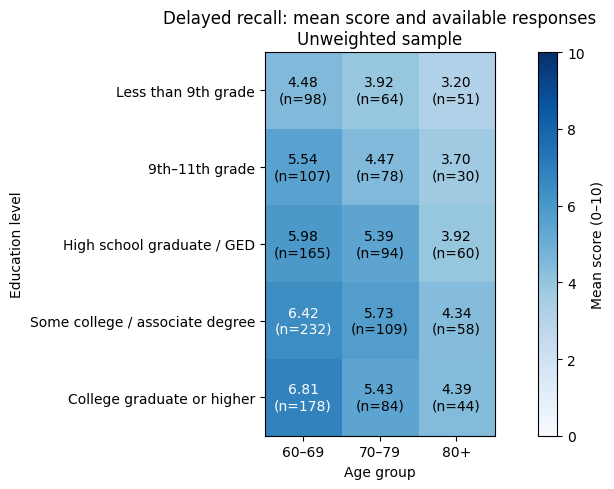

In [ ]:
# Visualize mean delayed recall scores by age and education.
import matplotlib.pyplot as plt

mean_table = recall_by_age_education.pivot(
    index="DMDEDUC2",
    columns="age_group",
    values="mean_score"
).reindex(index=[1, 2, 3, 4, 5], columns=["60–69", "70–79", "80+"])

count_table = recall_by_age_education.pivot(
    index="DMDEDUC2",
    columns="age_group",
    values="available_scores"
).reindex(index=[1, 2, 3, 4, 5], columns=["60–69", "70–79", "80+"])

fig, ax = plt.subplots(figsize=(9, 5))

heatmap = ax.imshow(mean_table, cmap="Blues", vmin=0, vmax=10)

ax.set_xticks(range(len(mean_table.columns)))
ax.set_xticklabels(mean_table.columns)
ax.set_yticks(range(len(mean_table.index)))
ax.set_yticklabels([education_labels[code] for code in mean_table.index])

for row in range(len(mean_table.index)):
    for col in range(len(mean_table.columns)):
        mean = mean_table.iloc[row, col]
        count = count_table.iloc[row, col]

        ax.text(
            col, row, f"{mean:.2f}\n(n={int(count)})",
            ha="center", va="center",
            color="white" if mean >= 6 else "black"
        )

ax.set_xlabel("Age group")
ax.set_ylabel("Education level")
ax.set_title("Delayed recall: mean score and available responses\nUnweighted sample")

fig.colorbar(heatmap, ax=ax, label="Mean score (0–10)")
plt.tight_layout()
plt.show()

In [ ]:
# Describe delayed recall scores by recorded sex.
recall_by_sex = (
    older_mec
    .groupby("RIAGENDR", dropna=False)
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDCSR", "count"),
        mean_score=("CFDCSR", "mean"),
        median_score=("CFDCSR", "median"),
        std_score=("CFDCSR", "std"),
    )
    .reset_index()
)

recall_by_sex["recorded_sex"] = (
    recall_by_sex["RIAGENDR"]
    .map({1: "Male", 2: "Female"})
    .fillna("Missing or unrecognized")
)

display(
    recall_by_sex[
        [
            "recorded_sex",
            "participants",
            "available_scores",
            "mean_score",
            "median_score",
            "std_score",
        ]
    ].round(2)
)

,recorded_sex,participants,available_scores,mean_score,median_score,std_score
0,Male,839,719,5.05,5.0,2.33
1,Female,848,735,5.78,6.0,2.39


### CERAD learning and delayed recall
Learning totals require all three trials. Paired comparisons use participants with both required scores.


In [ ]:
# Calculate and summarize the CERAD learning total.
learning_columns = ["CFDCST1", "CFDCST2", "CFDCST3"]

# Check the available scores before calculating the total.
learning_values = older_mec[learning_columns].stack().dropna()

assert learning_values.between(0, 10).all(), (
    "A CERAD learning score is outside the expected 0–10 range."
)

assert (learning_values % 1 == 0).all(), (
    "A CERAD learning score is not a whole number."
)

# min_count=3 leaves the total missing if any trial is missing.
older_mec["cerad_learning_total"] = (
    older_mec[learning_columns].sum(axis=1, min_count=3)
)

learning_summary = (
    older_mec["cerad_learning_total"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame(name="value")
    .round(2)
)

display(learning_summary)

print(
    "Participants without all three scores:",
    int(older_mec["cerad_learning_total"].isna().sum())
)

,value
count,1457.00
mean,17.70
median,18.00
std,4.86
min,0.00
max,29.00


Participants without all three scores: 230


In [ ]:
# Summarize each learning trial among participants
# with all three trial scores available.
complete_learning = older_mec.loc[
    older_mec["cerad_learning_total"].notna(),
    learning_columns
]

learning_by_trial = (
    complete_learning
    .agg(["count", "mean", "median", "std"])
    .transpose()
    .round(2)
)

learning_by_trial.index = [
    "Trial 1",
    "Trial 2",
    "Trial 3",
]

display(learning_by_trial)

,count,mean,median,std
Trial 1,1457.0,4.35,4.0,1.78
Trial 2,1457.0,6.29,6.0,1.85
Trial 3,1457.0,7.06,7.0,1.86


In [ ]:
# Compare Trial 3 and Trial 1 scores for each participant.
trial_change = complete_learning["CFDCST3"] - complete_learning["CFDCST1"]

change_summary = pd.DataFrame({
    "comparison": [
        "Trial 3 higher than Trial 1",
        "Trial 3 equal to Trial 1",
        "Trial 3 lower than Trial 1",
    ],
    "participants": [
        int((trial_change > 0).sum()),
        int((trial_change == 0).sum()),
        int((trial_change < 0).sum()),
    ],
})

change_summary["percentage"] = (
    100 * change_summary["participants"] / len(complete_learning)
).round(1)

display(change_summary)

,comparison,participants,percentage
0,Trial 3 higher than Trial 1,1359,93.3
1,Trial 3 equal to Trial 1,76,5.2
2,Trial 3 lower than Trial 1,22,1.5


In [ ]:
# Compare Trial 3 and delayed recall in participants
# with both scores available.
paired_recall = older_mec[["CFDCST3", "CFDCSR"]].dropna()

paired_summary = (
    paired_recall
    .agg(["count", "mean", "median", "std"])
    .transpose()
    .round(2)
)

paired_summary.index = [
    "Trial 3",
    "Delayed recall",
]

display(paired_summary)

print("Participants with both scores:", len(paired_recall))

,count,mean,median,std
Trial 3,1452.0,7.08,7.0,1.84
Delayed recall,1452.0,5.42,6.0,2.38


Participants with both scores: 1452


In [ ]:
# Compare delayed recall with Trial 3 for each participant.
recall_change = paired_recall["CFDCSR"] - paired_recall["CFDCST3"]

recall_change_summary = pd.DataFrame({
    "comparison": [
        "Delayed recall lower than Trial 3",
        "Delayed recall equal to Trial 3",
        "Delayed recall higher than Trial 3",
    ],
    "participants": [
        int((recall_change < 0).sum()),
        int((recall_change == 0).sum()),
        int((recall_change > 0).sum()),
    ],
})

recall_change_summary["percentage"] = (
    100 * recall_change_summary["participants"] / len(paired_recall)
).round(1)

display(recall_change_summary)

,comparison,participants,percentage
0,Delayed recall lower than Trial 3,1108,76.3
1,Delayed recall equal to Trial 3,241,16.6
2,Delayed recall higher than Trial 3,103,7.1


### Animal Fluency


In [ ]:
# Check and summarize available Animal Fluency scores.
animal_fluency = older_mec["CFDAST"]
available_fluency = animal_fluency.dropna()

assert (available_fluency >= 0).all(), (
    "An Animal Fluency score is negative."
)

assert (available_fluency % 1 == 0).all(), (
    "An Animal Fluency score is not a whole number."
)

fluency_summary = (
    available_fluency
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame(name="value")
    .round(2)
)

display(fluency_summary)

print("Missing scores:", int(animal_fluency.isna().sum()))

,value
count,1449.00
mean,16.20
median,16.00
std,5.55
min,1.00
max,40.00


Missing scores: 238


In [ ]:
# Describe Animal Fluency scores by age group.
fluency_by_age = (
    older_mec
    .groupby("age_group", observed=True)
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDAST", "count"),
        mean_score=("CFDAST", "mean"),
        median_score=("CFDAST", "median"),
        std_score=("CFDAST", "std"),
    )
    .round(2)
)

display(fluency_by_age)

,participants,available_scores,mean_score,median_score,std_score
age_group,,,,,
60–69,868,781,17.23,17.0,5.71
70–79,493,424,15.54,15.0,5.27
80+,326,244,14.06,14.0,4.67


In [ ]:
# Describe Animal Fluency scores by education level.
fluency_by_education = (
    older_mec
    .groupby("education_group")
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDAST", "count"),
        mean_score=("CFDAST", "mean"),
        median_score=("CFDAST", "median"),
        std_score=("CFDAST", "std"),
    )
    .round(2)
)

display(fluency_by_education)

,participants,available_scores,mean_score,median_score,std_score
education_group,,,,,
9th–11th grade,257,213,13.86,13.0,4.82
College graduate or higher,337,307,19.03,19.0,5.93
Don't know,3,1,11.00,11.0,NaN
High school graduate / GED,373,321,15.57,16.0,5.01
Less than 9th grade,285,209,13.48,14.0,4.31
Refused,1,1,17.00,17.0,NaN
Some college / associate degree,431,397,17.21,17.0,5.35


### Digit Symbol Substitution Test (DSST)


In [ ]:
# Check and summarize available DSST scores.
dsst = older_mec["CFDDS"]
available_dsst = dsst.dropna()

assert available_dsst.between(0, 133).all(), (
    "A DSST score is outside the expected 0–133 range."
)

assert (available_dsst % 1 == 0).all(), (
    "A DSST score is not a whole number."
)

dsst_summary = (
    available_dsst
    .agg(["count", "mean", "median", "std", "min", "max"])
    .to_frame(name="value")
    .round(2)
)

display(dsst_summary)

print("Missing scores:", int(dsst.isna().sum()))

,value
count,1422.00
mean,44.91
median,44.00
std,17.66
min,0.00
max,100.00


Missing scores: 265


In [ ]:
# Describe DSST scores by age group.
dsst_by_age = (
    older_mec
    .groupby("age_group", observed=True)
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDDS", "count"),
        mean_score=("CFDDS", "mean"),
        median_score=("CFDDS", "median"),
        std_score=("CFDDS", "std"),
    )
    .round(2)
)

display(dsst_by_age)

,participants,available_scores,mean_score,median_score,std_score
age_group,,,,,
60–69,868,782,48.73,49.0,17.96
70–79,493,414,42.30,42.0,16.62
80+,326,226,36.48,38.0,14.42


In [ ]:
# Describe DSST scores by education level.
dsst_by_education = (
    older_mec
    .groupby("education_group")
    .agg(
        participants=("SEQN", "size"),
        available_scores=("CFDDS", "count"),
        mean_score=("CFDDS", "mean"),
        median_score=("CFDDS", "median"),
        std_score=("CFDDS", "std"),
    )
    .round(2)
)

display(dsst_by_education)

,participants,available_scores,mean_score,median_score,std_score
education_group,,,,,
9th–11th grade,257,211,35.32,35.0,13.83
College graduate or higher,337,310,56.55,58.0,15.68
Don't know,3,1,20.00,20.0,NaN
High school graduate / GED,373,315,44.58,44.0,14.72
Less than 9th grade,285,190,25.67,24.0,11.82
Refused,1,1,57.00,57.0,NaN
Some college / associate degree,431,394,50.47,50.0,14.95


## 9. Survey design and the primary analysis sample
Preserve the full examined MEC sample and define the complete-case analysis subgroup separately.


In [ ]:
# Count records available for the planned primary analysis.
has_recall = older_mec["CFDCSR"].notna()

has_age = has_recall & older_mec["age_group"].notna()

has_education = has_age & older_mec["DMDEDUC2"].isin([1, 2, 3, 4, 5])

has_sex = has_education & older_mec["RIAGENDR"].isin([1, 2])

has_design = (
    has_sex
    & (older_mec["WTMEC2YR"] > 0)
    & older_mec["SDMVSTRA"].notna()
    & older_mec["SDMVPSU"].notna()
)

primary_sample_check = pd.DataFrame({
    "step": [
        "Participants aged 60+ examined at MEC",
        "With delayed recall score",
        "With a valid age group",
        "With a known education level",
        "With recorded sex",
        "With required survey design variables",
    ],
    "participants": [
        len(older_mec),
        int(has_recall.sum()),
        int(has_age.sum()),
        int(has_education.sum()),
        int(has_sex.sum()),
        int(has_design.sum()),
    ],
})

display(primary_sample_check)

,step,participants
0,Participants aged 60+ examined at MEC,1687
1,With delayed recall score,1454
2,With a valid age group,1454
3,With a known education level,1452
4,With recorded sex,1452
5,With required survey design variables,1452


In [ ]:
# Describe primary-analysis inclusion by age group.
inclusion_by_age = (
    older_mec
    .assign(primary_included=has_design)
    .groupby("age_group", observed=True)
    .agg(
        participants=("SEQN", "size"),
        included=("primary_included", "sum"),
    )
)

inclusion_by_age["excluded"] = (
    inclusion_by_age["participants"] - inclusion_by_age["included"]
)

inclusion_by_age["included_percentage"] = (
    100 * inclusion_by_age["included"]
    / inclusion_by_age["participants"]
).round(1)

display(inclusion_by_age)

,participants,included,excluded,included_percentage
age_group,,,,
60–69,868,780,88,89.9
70–79,493,429,64,87.0
80+,326,243,83,74.5


In [ ]:
# Inspect the survey design and the primary-analysis subgroup.
primary_ids = set(older_mec.loc[has_design, "SEQN"])

mec_design = nhanes_raw.loc[
    (nhanes_raw["RIDSTATR"] == 2)
    & (nhanes_raw["WTMEC2YR"] > 0)
].copy()

mec_design["in_primary_analysis"] = mec_design["SEQN"].isin(primary_ids)

# Count the subgroup within each stratum and sampling unit.
psu_check = (
    mec_design
    .groupby(["SDMVSTRA", "SDMVPSU"])
    .agg(
        mec_participants=("SEQN", "size"),
        primary_participants=("in_primary_analysis", "sum"),
    )
    .reset_index()
)

psu_check["has_primary_participants"] = (
    psu_check["primary_participants"] > 0
)

design_by_stratum = (
    psu_check
    .groupby("SDMVSTRA")
    .agg(
        sampling_units=("SDMVPSU", "size"),
        units_with_primary_participants=("has_primary_participants", "sum"),
        primary_participants=("primary_participants", "sum"),
    )
)

display(design_by_stratum)

print("MEC participants:", len(mec_design))
print("Primary-analysis participants:", int(mec_design["in_primary_analysis"].sum()))

,sampling_units,units_with_primary_participants,primary_participants
SDMVSTRA,,,
90.0,3,3,142
91.0,3,3,140
92.0,3,3,108
93.0,2,2,95
94.0,2,2,100
95.0,2,2,169
96.0,2,2,106
97.0,2,2,61
98.0,2,2,105


MEC participants: 9338
Primary-analysis participants: 1452


### Survey analysis software


In [ ]:
# Install and record the version used for these analyses.
import importlib.metadata
import subprocess
import sys

try:
    installed_svy_version = importlib.metadata.version("svy")
except importlib.metadata.PackageNotFoundError:
    installed_svy_version = None

if installed_svy_version != "0.36.0":
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "svy==0.36.0"
    ])

print("svy version:", importlib.metadata.version("svy"))


svy version: 0.36.0


In [ ]:
# Define the full MEC survey design.
import polars as pl
import svy

survey_columns = [
    "SEQN",
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "RIDAGEYR",
    "DMDEDUC2",
    "RIAGENDR",
    "CFDCSR",
    "in_primary_analysis",
]

# svy uses a Polars DataFrame.
survey_data = pl.from_pandas(mec_design[survey_columns])

survey_design = svy.Design(
    stratum="SDMVSTRA",
    psu="SDMVPSU",
    wgt="WTMEC2YR",
)

survey_sample = svy.Sample(
    data=survey_data,
    design=survey_design,
)

print(survey_sample)

╭─────────── Sample ────────────╮
│ Survey Data                   │
│   Rows     : 9338             │
│   Columns  : 9                │
│   Strata   : 14               │
│   PSUs     : 31               │
│                               │
│ Survey Design                 │
│   Case id            None     │
│   Wave               None     │
│   Stratum            SDMVSTRA │
│   PSU                SDMVPSU  │
│   SSU                None     │
│   Weight             WTMEC2YR │
│   With replacement   False    │
│   Prob               None     │
│   Hit                None     │
│   MOS                None     │
│   Population size    None     │
│   Replicate weights  None     │
╰───────────────────────────────╯

### Weighted delayed recall mean and numerical check


In [ ]:
# Estimate the weighted mean for the primary-analysis subgroup.
weighted_recall = survey_sample.estimation.mean(
    y="CFDCSR",
    where=svy.col("in_primary_analysis") == True,
)

print(weighted_recall)

# Independently check the weighted mean using Pandas.
primary_check = mec_design.loc[mec_design["in_primary_analysis"]]

manual_weighted_mean = (
    (primary_check["CFDCSR"] * primary_check["WTMEC2YR"]).sum()
    / primary_check["WTMEC2YR"].sum()
)

print(f"Manual weighted mean: {manual_weighted_mean:.4f}")

╭────────── Estimate: MEAN (TAYLOR) ───────────╮
│ y: CFDCSR                                    │
│ where: in_primary_analysis == true           │
│                                              │
│     est       se      lci      uci   cv (%)  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  5.7629   0.1188   5.5123   6.0134     2.06  │
│                                              │
╰──────────────────────────────────────────────╯


Manual weighted mean: 5.7629


In [ ]:
# Independently check the Taylor standard error for the weighted mean.
from scipy.stats import t

# Start from the full examined MEC sample.
taylor_check = mec_design[
    ["SDMVSTRA", "SDMVPSU", "WTMEC2YR", "CFDCSR", "in_primary_analysis"]
].copy()

# Participants outside the subgroup contribute zero to its estimate,
# but remain in the survey design.
taylor_check["linearized_value"] = 0.0

primary_mask = taylor_check["in_primary_analysis"]
weight_sum = taylor_check.loc[primary_mask, "WTMEC2YR"].sum()

taylor_check.loc[primary_mask, "linearized_value"] = (
    taylor_check.loc[primary_mask, "WTMEC2YR"]
    * (
        taylor_check.loc[primary_mask, "CFDCSR"]
        - manual_weighted_mean
    )
    / weight_sum
)

# Sum the linearized values within each sampling unit.
psu_totals = (
    taylor_check
    .groupby(["SDMVSTRA", "SDMVPSU"])["linearized_value"]
    .sum()
    .reset_index()
)

# Calculate the contribution of each stratum to the variance.
stratum_variances = []

for _, group in psu_totals.groupby("SDMVSTRA"):
    values = group["linearized_value"]
    number_of_psus = len(values)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    variance = (
        number_of_psus / (number_of_psus - 1)
        * ((values - values.mean()) ** 2).sum()
    )
    stratum_variances.append(variance)

manual_se = sum(stratum_variances) ** 0.5

# Survey design degrees of freedom: PSUs minus strata.
design_df = len(psu_totals) - psu_totals["SDMVSTRA"].nunique()
critical_value = t.ppf(0.975, df=design_df)

manual_lower = manual_weighted_mean - critical_value * manual_se
manual_upper = manual_weighted_mean + critical_value * manual_se

print(f"Manual weighted mean: {manual_weighted_mean:.4f}")
print(f"Manual standard error: {manual_se:.4f}")
print(f"Design degrees of freedom: {design_df}")
print(f"Manual 95% confidence interval: [{manual_lower:.4f}, {manual_upper:.4f}]")

Manual weighted mean: 5.7629
Manual standard error: 0.1188
Design degrees of freedom: 17
Manual 95% confidence interval: [5.5123, 6.0134]


## 10. Primary model: delayed verbal recall
The weighted linear model includes age group, education and recorded sex. Reference levels are 60–69 years, less than 9th grade and Female.


In [ ]:
# Prepare categorical variables for the primary model.
model_frame = mec_design.copy()

model_frame["age_model"] = pd.cut(
    model_frame["RIDAGEYR"],
    bins=[60, 70, 80, 81],
    labels=["60–69", "70–79", "80+"],
    right=False
).astype("string")

model_frame["education_model"] = (
    model_frame["DMDEDUC2"]
    .map(education_labels)
    .astype("string")
)

model_frame["sex_model"] = (
    model_frame["RIAGENDR"]
    .map({1: "Male", 2: "Female"})
    .astype("string")
)

# Check only participants marked for the primary analysis.
primary_model_rows = model_frame.loc[
    model_frame["in_primary_analysis"]
]

model_variable_check = pd.DataFrame({
    "variable": [
        "Delayed recall",
        "Age group",
        "Education",
        "Recorded sex",
    ],
    "missing_values": [
        int(primary_model_rows["CFDCSR"].isna().sum()),
        int(primary_model_rows["age_model"].isna().sum()),
        int(primary_model_rows["education_model"].isna().sum()),
        int(primary_model_rows["sex_model"].isna().sum()),
    ],
})

print("Primary-analysis participants:", len(primary_model_rows))
display(model_variable_check)

Primary-analysis participants: 1452


,variable,missing_values
0,Delayed recall,0
1,Age group,0
2,Education,0
3,Recorded sex,0


In [ ]:
# Fit the primary survey-weighted linear model.
model_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "CFDCSR",
    "age_model",
    "education_model",
    "sex_model",
    "in_primary_analysis",
]

model_data = pl.from_pandas(model_frame[model_columns])

model_sample = svy.Sample(
    data=model_data,
    design=survey_design,
)

primary_model = model_sample.glm.fit(
    y="CFDCSR",
    x=[
        svy.Cat("age_model", ref="60–69"),
        svy.Cat("education_model", ref="Less than 9th grade"),
        svy.Cat("sex_model", ref="Female"),
    ],
    family="gaussian",
    where=svy.col("in_primary_analysis") == True,
)

print(primary_model)

╭──────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: CFDCSR                                                                                                  │
│ where: in_primary_analysis == true                                                                                │
│                                                                                                                   │
│ Observations       1452  AIC           6288.1471                                                                  │
│ DF Residuals         10  BIC                   -                                                                  │
│ Deviance      6313.1190  Scale            4.3720                                                                  │
│ R-squared       0.20267  R-sq (adj)      0.19880                                                                  │
│                          Iterations            2                                                                  │
│ F-stat (adj)   44.13315  Prob (F-adj)     0.0013                                                                  │
│                                                                                                                   │
│                                                                                                                   │
│  Term                                                 Coef.   Std.Err.          t    P>|t|     [0.025     0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                        5.69882    0.32411   17.58326   <0.001    4.97667    6.42097  │
│  age_model_70–79                                   -1.00434    0.21672   -4.63427   <0.001   -1.48723   -0.52146  │
│  age_model_80+                                     -2.20024    0.30108   -7.30778   <0.001   -2.87110   -1.52939  │
│  education_model_9th–11th grade                     0.47186    0.23731    1.98837   0.0748   -0.05690    1.00062  │
│  education_model_College graduate or higher         1.41601    0.35566    3.98139   0.0026    0.62356    2.20847  │
│  education_model_High school graduate / GED         0.88385    0.27865    3.17189   0.0100    0.26298    1.50472  │
│  education_model_Some college / associate degree    1.39793    0.27514    5.08077   <0.001    0.78487    2.01098  │
│  sex_model_Male                                    -0.87033    0.13109   -6.63929   <0.001   -1.16241   -0.57825  │
│                                                                                                                   │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

### Numerical checks
The following manual calculations use the same input data and assumptions as `svy`; they are arithmetic cross-checks, not independent software replication.


In [ ]:
# Independently check the weighted regression coefficients.
import numpy as np

# Select the same complete-case subgroup used in the model.
manual_model_data = model_frame.loc[
    model_frame["in_primary_analysis"]
].copy()

# Build the same reference categories used by svy.
X = pd.DataFrame(
    {
        "_intercept_": 1.0,
        "age_model_70–79": (
            manual_model_data["age_model"] == "70–79"
        ).astype(float),
        "age_model_80+": (
            manual_model_data["age_model"] == "80+"
        ).astype(float),
        "education_model_9th–11th grade": (
            manual_model_data["education_model"] == "9th–11th grade"
        ).astype(float),
        "education_model_College graduate or higher": (
            manual_model_data["education_model"] == "College graduate or higher"
        ).astype(float),
        "education_model_High school graduate / GED": (
            manual_model_data["education_model"] == "High school graduate / GED"
        ).astype(float),
        "education_model_Some college / associate degree": (
            manual_model_data["education_model"] == "Some college / associate degree"
        ).astype(float),
        "sex_model_Male": (
            manual_model_data["sex_model"] == "Male"
        ).astype(float),
    },
    index=manual_model_data.index,
)

y = manual_model_data["CFDCSR"].to_numpy(dtype=float)
weights = manual_model_data["WTMEC2YR"].to_numpy(dtype=float)
X_array = X.to_numpy(dtype=float)

# Solve the weighted least-squares equations.
sqrt_weights = np.sqrt(weights)

manual_coefficients = np.linalg.lstsq(
    X_array * sqrt_weights[:, None],
    y * sqrt_weights,
    rcond=None,
)[0]

manual_results = pd.DataFrame({
    "term": X.columns,
    "manual_coefficient": manual_coefficients,
})

# Compare with the coefficients reported by svy.
svy_results = primary_model.to_polars().to_pandas()[
    ["term", "estimate"]
]

coefficient_check = manual_results.merge(
    svy_results,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (coefficient_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

coefficient_check["difference"] = (
    coefficient_check["manual_coefficient"]
    - coefficient_check["estimate"]
)

display(
    coefficient_check[
        ["term", "manual_coefficient", "estimate", "difference"]
    ].round(6)
)

,term,manual_coefficient,estimate,difference
0,_intercept_,5.698824,5.698824,-0.0
1,age_model_70–79,-1.004343,-1.004343,0.0
2,age_model_80+,-2.200242,-2.200242,0.0
3,education_model_9th–11th grade,0.471859,0.471859,0.0
4,education_model_College graduate or higher,1.416013,1.416013,0.0
5,education_model_High school graduate / GED,0.883851,0.883851,0.0
6,education_model_Some college / associate degree,1.397927,1.397927,0.0
7,sex_model_Male,-0.870327,-0.870327,-0.0


In [ ]:
# Independently check Taylor standard errors for the regression.
# Calculate residuals for the primary-analysis participants.
residuals = y - X_array @ manual_coefficients

# Start with zero contributions for every MEC participant.
score_columns = list(X.columns)

score_components = pd.DataFrame(
    0.0,
    index=model_frame.index,
    columns=score_columns,
)

# Add weighted contributions for participants in the model.
score_components.loc[manual_model_data.index, score_columns] = (
    X_array * (weights * residuals)[:, None]
)

score_components = model_frame[["SDMVSTRA", "SDMVPSU"]].join(
    score_components
)

# Sum contributions within each sampling unit and stratum.
scores_by_psu = (
    score_components
    .groupby(["SDMVSTRA", "SDMVPSU"])[score_columns]
    .sum()
)

# Calculate the between-unit contribution within each stratum.
meat = np.zeros((len(score_columns), len(score_columns)))

for _, stratum in scores_by_psu.groupby(level="SDMVSTRA"):
    psu_scores = stratum.to_numpy()
    number_of_psus = len(psu_scores)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    centered_scores = psu_scores - psu_scores.mean(axis=0)

    meat += (
        number_of_psus / (number_of_psus - 1)
        * centered_scores.T @ centered_scores
    )

# Complete the sandwich variance calculation.
bread = X_array.T @ (weights[:, None] * X_array)
bread_inverse = np.linalg.inv(bread)

manual_covariance = bread_inverse @ meat @ bread_inverse.T
manual_standard_errors = np.sqrt(np.diag(manual_covariance))

manual_se_results = pd.DataFrame({
    "term": score_columns,
    "manual_standard_error": manual_standard_errors,
})

svy_se_results = primary_model.to_polars().to_pandas()[
    ["term", "std_err"]
]

standard_error_check = manual_se_results.merge(
    svy_se_results,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (standard_error_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

standard_error_check["difference"] = (
    standard_error_check["manual_standard_error"]
    - standard_error_check["std_err"]
)

display(
    standard_error_check[
        ["term", "manual_standard_error", "std_err", "difference"]
    ].round(6)
)

,term,manual_standard_error,std_err,difference
0,_intercept_,0.324105,0.324105,-0.0
1,age_model_70–79,0.216721,0.216721,-0.0
2,age_model_80+,0.301082,0.301082,0.0
3,education_model_9th–11th grade,0.237309,0.237309,-0.0
4,education_model_College graduate or higher,0.355657,0.355657,-0.0
5,education_model_High school graduate / GED,0.278651,0.278651,-0.0
6,education_model_Some college / associate degree,0.275141,0.275141,0.0
7,sex_model_Male,0.131087,0.131087,0.0


In [ ]:
# Check the model's 95% confidence intervals.
number_of_coefficients = X_array.shape[1]

# Design degrees of freedom minus non-intercept coefficients.
manual_model_df = design_df - (number_of_coefficients - 1)

critical_value_model = t.ppf(0.975, df=manual_model_df)

manual_intervals = pd.DataFrame({
    "term": X.columns,
    "manual_lower": (
        manual_coefficients
        - critical_value_model * manual_standard_errors
    ),
    "manual_upper": (
        manual_coefficients
        + critical_value_model * manual_standard_errors
    ),
})

svy_intervals = primary_model.to_polars().to_pandas()[
    ["term", "conf_low", "conf_high", "df"]
]

interval_check = manual_intervals.merge(
    svy_intervals,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (interval_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

interval_check["lower_difference"] = (
    interval_check["manual_lower"] - interval_check["conf_low"]
)

interval_check["upper_difference"] = (
    interval_check["manual_upper"] - interval_check["conf_high"]
)

print("Design degrees of freedom:", design_df)
print("Manual model degrees of freedom:", manual_model_df)

display(
    interval_check[
        [
            "term",
            "df",
            "manual_lower",
            "conf_low",
            "lower_difference",
            "manual_upper",
            "conf_high",
            "upper_difference",
        ]
    ].round(6)
)

Design degrees of freedom: 17
Manual model degrees of freedom: 10


,term,df,manual_lower,conf_low,lower_difference,manual_upper,conf_high,upper_difference
0,_intercept_,10,4.976672,4.976672,-0.0,6.420975,6.420975,-0.0
1,age_model_70–79,10,-1.487227,-1.487227,0.0,-0.521459,-0.521459,0.0
2,age_model_80+,10,-2.871096,-2.871096,0.0,-1.529389,-1.529389,0.0
3,education_model_9th–11th grade,10,-0.056899,-0.056899,0.0,1.000617,1.000617,0.0
4,education_model_College graduate or higher,10,0.623558,0.623558,0.0,2.208467,2.208467,0.0
5,education_model_High school graduate / GED,10,0.262978,0.262978,0.0,1.504724,1.504724,0.0
6,education_model_Some college / associate degree,10,0.784875,0.784875,0.0,2.010978,2.010978,0.0
7,sex_model_Male,10,-1.162408,-1.162408,-0.0,-0.578246,-0.578246,-0.0


### Model diagnostics
The residual summaries and plots are unweighted exploratory diagnostics, not definitive tests of model adequacy.


In [ ]:
# Check whether fitted values stay within the score's possible range.
fitted_values = X_array @ manual_coefficients

prediction_check = pd.DataFrame({
    "check": [
        "Participants in the model",
        "Lowest fitted value",
        "Highest fitted value",
        "Fitted values below 0",
        "Fitted values above 10",
    ],
    "value": [
        len(fitted_values),
        fitted_values.min(),
        fitted_values.max(),
        int((fitted_values < 0).sum()),
        int((fitted_values > 10).sum()),
    ],
})

display(prediction_check.round(3))

,check,value
0,Participants in the model,1452.000
1,Lowest fitted value,2.628
2,Highest fitted value,7.115
3,Fitted values below 0,0.000
4,Fitted values above 10,0.000


In [ ]:
# Inspect floor and ceiling scores within the model sample.
model_extremes = manual_model_data.assign(
    score_zero=manual_model_data["CFDCSR"].eq(0),
    score_ten=manual_model_data["CFDCSR"].eq(10),
)

extremes_by_age = (
    model_extremes
    .groupby("age_model", observed=True)
    .agg(
        participants=("CFDCSR", "count"),
        scores_zero=("score_zero", "sum"),
        scores_ten=("score_ten", "sum"),
    )
)

extremes_by_age["zero_percentage"] = (
    100 * extremes_by_age["scores_zero"]
    / extremes_by_age["participants"]
).round(1)

extremes_by_age["ten_percentage"] = (
    100 * extremes_by_age["scores_ten"]
    / extremes_by_age["participants"]
).round(1)

display(extremes_by_age)


,participants,scores_zero,scores_ten,zero_percentage,ten_percentage
age_model,,,,,
60–69,780,19,21,2.4,2.7
70–79,429,24,2,5.6,0.5
80+,243,27,0,11.1,0.0


In [ ]:
# Describe model residuals by age group.
model_diagnostics = manual_model_data.assign(
    residual=residuals
)

residuals_by_age = (
    model_diagnostics
    .groupby("age_model", observed=True)
    .agg(
        participants=("residual", "size"),
        residual_std=("residual", "std"),
        residual_10th_percentile=(
            "residual", lambda values: values.quantile(0.10)
        ),
        residual_90th_percentile=(
            "residual", lambda values: values.quantile(0.90)
        ),
    )
    .round(2)
)

display(residuals_by_age)

,participants,residual_std,residual_10th_percentile,residual_90th_percentile
age_model,,,,
60–69,780,2.01,-2.83,1.90
70–79,429,2.25,-3.18,2.78
80+,243,2.30,-3.38,2.94


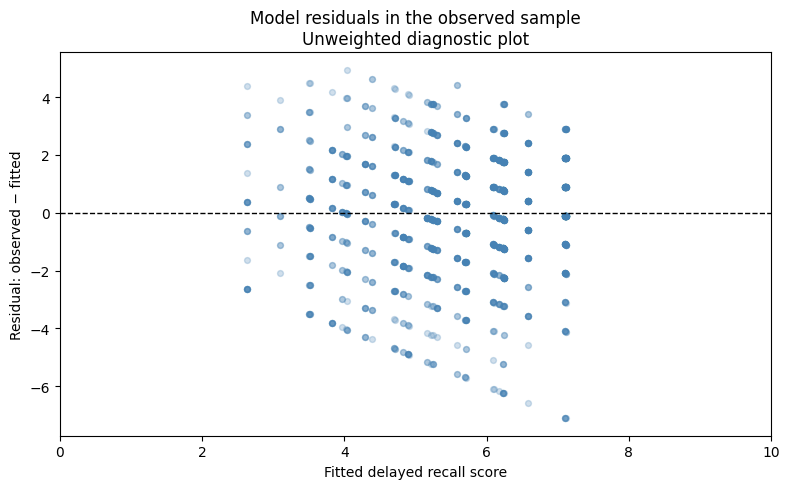

In [ ]:
# Plot observed residuals against fitted scores.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    fitted_values,
    residuals,
    alpha=0.25,
    s=18,
    color="steelblue",
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlim(0, 10)
ax.set_xlabel("Fitted delayed recall score")
ax.set_ylabel("Residual: observed − fitted")
ax.set_title("Model residuals in the observed sample\nUnweighted diagnostic plot")

plt.tight_layout()
plt.show()

### Comparison without recorded sex
Both models use the same complete-case sample. Differences between estimates are descriptive, not causal effects.


In [ ]:
# Fit a survey-weighted model with age and education only.
model_without_sex = model_sample.glm.fit(
    y="CFDCSR",
    x=[
        svy.Cat("age_model", ref="60–69"),
        svy.Cat("education_model", ref="Less than 9th grade"),
    ],
    family="gaussian",
    where=svy.col("in_primary_analysis") == True,
)

print(model_without_sex)

╭──────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: CFDCSR                                                                                                  │
│ where: in_primary_analysis == true                                                                                │
│                                                                                                                   │
│ Observations       1452  AIC           6345.1533                                                                  │
│ DF Residuals         11  BIC                   -                                                                  │
│ Deviance      6579.3365  Scale            4.5532                                                                  │
│ R-squared       0.16904  R-sq (adj)      0.16559                                                                  │
│                          Iterations            2                                                                  │
│ F-stat (adj)   15.57368  Prob (F-adj)     0.0020                                                                  │
│                                                                                                                   │
│                                                                                                                   │
│  Term                                                 Coef.   Std.Err.          t    P>|t|     [0.025     0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                        5.26615    0.32465   16.22098   <0.001    4.55160    5.98070  │
│  age_model_70–79                                   -0.99296    0.21353   -4.65015   <0.001   -1.46294   -0.52298  │
│  age_model_80+                                     -2.12157    0.32998   -6.42931   <0.001   -2.84786   -1.39528  │
│  education_model_9th–11th grade                     0.50359    0.23202    2.17046   0.0527   -0.00708    1.01426  │
│  education_model_College graduate or higher         1.36637    0.36348    3.75913   0.0032    0.56636    2.16639  │
│  education_model_High school graduate / GED         0.94902    0.25818    3.67575   0.0037    0.38076    1.51727  │
│  education_model_Some college / associate degree    1.47952    0.27344    5.41066   <0.001    0.87767    2.08137  │
│                                                                                                                   │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
# Independently check the model without recorded sex.
reduced_columns = [
    column for column in X.columns
    if column != "sex_model_Male"
]

X_reduced = X[reduced_columns].to_numpy(dtype=float)

# Weighted regression coefficients.
reduced_coefficients = np.linalg.lstsq(
    X_reduced * sqrt_weights[:, None],
    y * sqrt_weights,
    rcond=None,
)[0]

reduced_residuals = y - X_reduced @ reduced_coefficients

# Keep all MEC participants in the survey design.
reduced_scores = pd.DataFrame(
    0.0,
    index=model_frame.index,
    columns=reduced_columns,
)

reduced_scores.loc[manual_model_data.index, reduced_columns] = (
    X_reduced * (weights * reduced_residuals)[:, None]
)

reduced_scores = model_frame[["SDMVSTRA", "SDMVPSU"]].join(
    reduced_scores
)

reduced_psu_scores = (
    reduced_scores
    .groupby(["SDMVSTRA", "SDMVPSU"])[reduced_columns]
    .sum()
)

reduced_meat = np.zeros(
    (len(reduced_columns), len(reduced_columns))
)

for _, stratum in reduced_psu_scores.groupby(level="SDMVSTRA"):
    psu_values = stratum.to_numpy()
    number_of_psus = len(psu_values)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    centered = psu_values - psu_values.mean(axis=0)

    reduced_meat += (
        number_of_psus / (number_of_psus - 1)
        * centered.T @ centered
    )

reduced_bread = X_reduced.T @ (weights[:, None] * X_reduced)
reduced_bread_inverse = np.linalg.inv(reduced_bread)

reduced_covariance = (
    reduced_bread_inverse @ reduced_meat @ reduced_bread_inverse.T
)

reduced_standard_errors = np.sqrt(np.diag(reduced_covariance))

# Compare manual results with svy.
reduced_manual_results = pd.DataFrame({
    "term": reduced_columns,
    "manual_coefficient": reduced_coefficients,
    "manual_standard_error": reduced_standard_errors,
})

reduced_svy_results = model_without_sex.to_polars().to_pandas()[
    ["term", "estimate", "std_err"]
]

reduced_check = reduced_manual_results.merge(
    reduced_svy_results,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (reduced_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

reduced_check["coefficient_difference"] = (
    reduced_check["manual_coefficient"] - reduced_check["estimate"]
)

reduced_check["standard_error_difference"] = (
    reduced_check["manual_standard_error"] - reduced_check["std_err"]
)

display(
    reduced_check[
        [
            "term",
            "estimate",
            "coefficient_difference",
            "std_err",
            "standard_error_difference",
        ]
    ].round(6)
)

,term,estimate,coefficient_difference,std_err,standard_error_difference
0,_intercept_,5.266150,-0.0,0.324650,-0.0
1,age_model_70–79,-0.992958,0.0,0.213532,-0.0
2,age_model_80+,-2.121568,0.0,0.329984,0.0
3,education_model_9th–11th grade,0.503589,0.0,0.232020,-0.0
4,education_model_College graduate or higher,1.366373,0.0,0.363481,-0.0
5,education_model_High school graduate / GED,0.949017,0.0,0.258183,-0.0
6,education_model_Some college / associate degree,1.479517,0.0,0.273445,-0.0


In [ ]:
# Check confidence intervals for the model without recorded sex.
reduced_model_df = design_df - (len(reduced_columns) - 1)

reduced_critical_value = t.ppf(
    0.975,
    df=reduced_model_df,
)

reduced_manual_intervals = pd.DataFrame({
    "term": reduced_columns,
    "manual_lower": (
        reduced_coefficients
        - reduced_critical_value * reduced_standard_errors
    ),
    "manual_upper": (
        reduced_coefficients
        + reduced_critical_value * reduced_standard_errors
    ),
})

reduced_svy_intervals = model_without_sex.to_polars().to_pandas()[
    ["term", "conf_low", "conf_high", "df"]
]

reduced_interval_check = reduced_manual_intervals.merge(
    reduced_svy_intervals,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (reduced_interval_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

reduced_interval_check["lower_difference"] = (
    reduced_interval_check["manual_lower"]
    - reduced_interval_check["conf_low"]
)

reduced_interval_check["upper_difference"] = (
    reduced_interval_check["manual_upper"]
    - reduced_interval_check["conf_high"]
)

print("Design degrees of freedom:", design_df)
print("Manual model degrees of freedom:", reduced_model_df)

display(
    reduced_interval_check[
        [
            "term",
            "df",
            "conf_low",
            "lower_difference",
            "conf_high",
            "upper_difference",
        ]
    ].round(6)
)

Design degrees of freedom: 17
Manual model degrees of freedom: 11


,term,df,conf_low,lower_difference,conf_high,upper_difference
0,_intercept_,11,4.551599,-0.0,5.980701,-0.0
1,age_model_70–79,11,-1.462940,0.0,-0.522977,0.0
2,age_model_80+,11,-2.847858,0.0,-1.395279,0.0
3,education_model_9th–11th grade,11,-0.007083,0.0,1.014262,0.0
4,education_model_College graduate or higher,11,0.566357,0.0,2.166389,0.0
5,education_model_High school graduate / GED,11,0.380760,0.0,1.517274,0.0
6,education_model_Some college / associate degree,11,0.877669,0.0,2.081365,0.0


In [ ]:
# Compare age and education coefficients across the two models.
without_sex = (
    model_without_sex.to_polars().to_pandas()[["term", "estimate"]]
    .rename(columns={"estimate": "without_sex"})
)

with_sex = (
    primary_model.to_polars().to_pandas()[["term", "estimate"]]
    .rename(columns={"estimate": "with_sex"})
)

model_comparison = without_sex.merge(
    with_sex,
    on="term",
    how="inner",
    validate="one_to_one",
)

# The intercept has a different interpretation across the models.
model_comparison = model_comparison.loc[
    model_comparison["term"] != "_intercept_"
].copy()

model_comparison["change"] = (
    model_comparison["with_sex"]
    - model_comparison["without_sex"]
)

display(model_comparison.round(3))

,term,without_sex,with_sex,change
1,age_model_70–79,-0.993,-1.004,-0.011
2,age_model_80+,-2.122,-2.200,-0.079
3,education_model_9th–11th grade,0.504,0.472,-0.032
4,education_model_College graduate or higher,1.366,1.416,0.050
5,education_model_High school graduate / GED,0.949,0.884,-0.065
6,education_model_Some college / associate degree,1.480,1.398,-0.082


## 11. Secondary cognitive outcomes
The outcomes use distinct scales and may include different participants. Interpret secondary comparisons as exploratory.


In [ ]:
# Count available cases for the secondary analyses.
valid_predictors = (
    model_frame["age_model"].notna()
    & model_frame["DMDEDUC2"].isin([1, 2, 3, 4, 5])
    & model_frame["RIAGENDR"].isin([1, 2])
    & model_frame["SDMVSTRA"].notna()
    & model_frame["SDMVPSU"].notna()
    & (model_frame["WTMEC2YR"] > 0)
)

secondary_sample_check = pd.DataFrame({
    "outcome": [
        "Animal Fluency",
        "DSST",
    ],
    "available_scores_age_60_plus": [
        int(
            (
                model_frame["age_model"].notna()
                & model_frame["CFDAST"].notna()
            ).sum()
        ),
        int(
            (
                model_frame["age_model"].notna()
                & model_frame["CFDDS"].notna()
            ).sum()
        ),
    ],
    "complete_cases_for_model": [
        int((valid_predictors & model_frame["CFDAST"].notna()).sum()),
        int((valid_predictors & model_frame["CFDDS"].notna()).sum()),
    ],
})

display(secondary_sample_check)

,outcome,available_scores_age_60_plus,complete_cases_for_model
0,Animal Fluency,1449,1447
1,DSST,1422,1420


In [ ]:
# Prepare the CERAD learning total for the survey model.
learning_columns = ["CFDCST1", "CFDCST2", "CFDCST3"]

model_frame["cerad_learning_total"] = (
    model_frame[learning_columns].sum(axis=1, min_count=3)
)

learning_sample_check = pd.DataFrame({
    "outcome": ["CERAD learning total"],
    "available_scores_age_60_plus": [
        int(
            (
                model_frame["age_model"].notna()
                & model_frame["cerad_learning_total"].notna()
            ).sum()
        )
    ],
    "complete_cases_for_model": [
        int(
            (
                valid_predictors
                & model_frame["cerad_learning_total"].notna()
            ).sum()
        )
    ],
})

display(learning_sample_check)

,outcome,available_scores_age_60_plus,complete_cases_for_model
0,CERAD learning total,1457,1455


### CERAD learning model


In [ ]:
# Fit the survey-weighted CERAD learning model.
model_frame["in_learning_analysis"] = (
    valid_predictors
    & model_frame["cerad_learning_total"].notna()
)

learning_model_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "cerad_learning_total",
    "age_model",
    "education_model",
    "sex_model",
    "in_learning_analysis",
]

learning_model_data = pl.from_pandas(
    model_frame[learning_model_columns]
)

learning_model_sample = svy.Sample(
    data=learning_model_data,
    design=survey_design,
)

learning_model = learning_model_sample.glm.fit(
    y="cerad_learning_total",
    x=[
        svy.Cat("age_model", ref="60–69"),
        svy.Cat("education_model", ref="Less than 9th grade"),
        svy.Cat("sex_model", ref="Female"),
    ],
    family="gaussian",
    where=svy.col("in_learning_analysis") == True,
)

print(learning_model)

╭──────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: cerad_learning_total                                                                                    │
│ where: in_learning_analysis == true                                                                               │
│                                                                                                                   │
│ Observations        1455  AIC           8258.2827                                                                 │
│ DF Residuals          10  BIC                   -                                                                 │
│ Deviance      24409.6641  Scale           16.8692                                                                 │
│ R-squared        0.23277  R-sq (adj)      0.22906                                                                 │
│                           Iterations            2                                                                 │
│ F-stat (adj)    38.27342  Prob (F-adj)     0.0017                                                                 │
│                                                                                                                   │
│                                                                                                                   │
│  Term                                                 Coef.   Std.Err.          t    P>|t|     [0.025     0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                       17.26256    0.50738   34.02272   <0.001   16.13204   18.39308  │
│  age_model_70–79                                   -1.92359    0.25471   -7.55216   <0.001   -2.49111   -1.35607  │
│  age_model_80+                                     -4.02055    0.57964   -6.93630   <0.001   -5.31206   -2.72903  │
│  education_model_9th–11th grade                     1.72409    0.49422    3.48854   0.0058    0.62291    2.82527  │
│  education_model_College graduate or higher         4.62794    0.51486    8.98878   <0.001    3.48077    5.77511  │
│  education_model_High school graduate / GED         2.87297    0.40329    7.12383   <0.001    1.97438    3.77156  │
│  education_model_Some college / associate degree    3.77906    0.48360    7.81443   <0.001    2.70153    4.85659  │
│  sex_model_Male                                    -1.67759    0.29766   -5.63602   <0.001   -2.34081   -1.01438  │
│                                                                                                                   │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
# Independently check the CERAD learning model coefficients.
learning_rows = model_frame.loc[
    model_frame["in_learning_analysis"]
].copy()

learning_X = pd.DataFrame(index=learning_rows.index)
learning_X["_intercept_"] = 1.0

learning_X["age_model_70–79"] = (
    learning_rows["age_model"] == "70–79"
).astype(float)

learning_X["age_model_80+"] = (
    learning_rows["age_model"] == "80+"
).astype(float)

learning_X["education_model_9th–11th grade"] = (
    learning_rows["education_model"] == "9th–11th grade"
).astype(float)

learning_X["education_model_College graduate or higher"] = (
    learning_rows["education_model"] == "College graduate or higher"
).astype(float)

learning_X["education_model_High school graduate / GED"] = (
    learning_rows["education_model"] == "High school graduate / GED"
).astype(float)

learning_X["education_model_Some college / associate degree"] = (
    learning_rows["education_model"] == "Some college / associate degree"
).astype(float)

learning_X["sex_model_Male"] = (
    learning_rows["sex_model"] == "Male"
).astype(float)

learning_X_array = learning_X.to_numpy(dtype=float)
learning_y = learning_rows["cerad_learning_total"].to_numpy(dtype=float)
learning_weights = learning_rows["WTMEC2YR"].to_numpy(dtype=float)

learning_sqrt_weights = np.sqrt(learning_weights)

learning_manual_coefficients = np.linalg.lstsq(
    learning_X_array * learning_sqrt_weights[:, None],
    learning_y * learning_sqrt_weights,
    rcond=None,
)[0]

learning_manual_results = pd.DataFrame({
    "term": learning_X.columns,
    "manual_coefficient": learning_manual_coefficients,
})

learning_svy_results = learning_model.to_polars().to_pandas()[
    ["term", "estimate"]
]

learning_coefficient_check = learning_manual_results.merge(
    learning_svy_results,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (learning_coefficient_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

learning_coefficient_check["difference"] = (
    learning_coefficient_check["manual_coefficient"]
    - learning_coefficient_check["estimate"]
)

print("Participants:", len(learning_rows))
print("Strata:", learning_rows["SDMVSTRA"].nunique())
print(
    "Sampling units:",
    len(learning_rows[["SDMVSTRA", "SDMVPSU"]].drop_duplicates())
)

display(
    learning_coefficient_check[
        ["term", "manual_coefficient", "estimate", "difference"]
    ].round(6)
)

Participants: 1455
Strata: 14
Sampling units: 31


,term,manual_coefficient,estimate,difference
0,_intercept_,17.262562,17.262562,0.0
1,age_model_70–79,-1.923588,-1.923588,-0.0
2,age_model_80+,-4.020547,-4.020547,-0.0
3,education_model_9th–11th grade,1.724092,1.724092,-0.0
4,education_model_College graduate or higher,4.627939,4.627939,-0.0
5,education_model_High school graduate / GED,2.872971,2.872971,-0.0
6,education_model_Some college / associate degree,3.779059,3.779059,-0.0
7,sex_model_Male,-1.677593,-1.677593,0.0


In [ ]:
# Independently check Taylor standard errors for the learning model.
learning_residuals = (
    learning_y - learning_X_array @ learning_manual_coefficients
)

learning_score_columns = list(learning_X.columns)

# Start with zero contributions for all MEC participants.
learning_scores = pd.DataFrame(
    0.0,
    index=model_frame.index,
    columns=learning_score_columns,
)

learning_scores.loc[learning_rows.index, learning_score_columns] = (
    learning_X_array
    * (learning_weights * learning_residuals)[:, None]
)

learning_scores = model_frame[["SDMVSTRA", "SDMVPSU"]].join(
    learning_scores
)

learning_psu_scores = (
    learning_scores
    .groupby(["SDMVSTRA", "SDMVPSU"])[learning_score_columns]
    .sum()
)

learning_meat = np.zeros(
    (len(learning_score_columns), len(learning_score_columns))
)

for _, stratum in learning_psu_scores.groupby(level="SDMVSTRA"):
    psu_values = stratum.to_numpy()
    number_of_psus = len(psu_values)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    centered = psu_values - psu_values.mean(axis=0)

    learning_meat += (
        number_of_psus / (number_of_psus - 1)
        * centered.T @ centered
    )

learning_bread = (
    learning_X_array.T
    @ (learning_weights[:, None] * learning_X_array)
)

learning_bread_inverse = np.linalg.inv(learning_bread)

learning_covariance = (
    learning_bread_inverse
    @ learning_meat
    @ learning_bread_inverse.T
)

learning_manual_se = np.sqrt(np.diag(learning_covariance))

learning_se_results = pd.DataFrame({
    "term": learning_score_columns,
    "manual_standard_error": learning_manual_se,
})

learning_svy_se = learning_model.to_polars().to_pandas()[
    ["term", "std_err"]
]

learning_se_check = learning_se_results.merge(
    learning_svy_se,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (learning_se_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

learning_se_check["difference"] = (
    learning_se_check["manual_standard_error"]
    - learning_se_check["std_err"]
)

display(
    learning_se_check[
        ["term", "manual_standard_error", "std_err", "difference"]
    ].round(6)
)

,term,manual_standard_error,std_err,difference
0,_intercept_,0.507383,0.507383,-0.0
1,age_model_70–79,0.254707,0.254707,-0.0
2,age_model_80+,0.579638,0.579638,-0.0
3,education_model_9th–11th grade,0.494216,0.494216,-0.0
4,education_model_College graduate or higher,0.514857,0.514857,-0.0
5,education_model_High school graduate / GED,0.403290,0.403290,-0.0
6,education_model_Some college / associate degree,0.483600,0.483600,-0.0
7,sex_model_Male,0.297655,0.297655,0.0


In [ ]:
# Check confidence intervals for the CERAD learning model.
learning_design_df = (
    len(learning_rows[["SDMVSTRA", "SDMVPSU"]].drop_duplicates())
    - learning_rows["SDMVSTRA"].nunique()
)

learning_model_df = (
    learning_design_df - (len(learning_score_columns) - 1)
)

learning_critical_value = t.ppf(
    0.975,
    df=learning_model_df,
)

learning_manual_intervals = pd.DataFrame({
    "term": learning_score_columns,
    "manual_lower": (
        learning_manual_coefficients
        - learning_critical_value * learning_manual_se
    ),
    "manual_upper": (
        learning_manual_coefficients
        + learning_critical_value * learning_manual_se
    ),
})

learning_svy_intervals = learning_model.to_polars().to_pandas()[
    ["term", "conf_low", "conf_high", "df"]
]

learning_interval_check = learning_manual_intervals.merge(
    learning_svy_intervals,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (learning_interval_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

learning_interval_check["lower_difference"] = (
    learning_interval_check["manual_lower"]
    - learning_interval_check["conf_low"]
)

learning_interval_check["upper_difference"] = (
    learning_interval_check["manual_upper"]
    - learning_interval_check["conf_high"]
)

print("Design degrees of freedom:", learning_design_df)
print("Manual model degrees of freedom:", learning_model_df)

display(
    learning_interval_check[
        [
            "term",
            "df",
            "conf_low",
            "lower_difference",
            "conf_high",
            "upper_difference",
        ]
    ].round(6)
)

Design degrees of freedom: 17
Manual model degrees of freedom: 10


,term,df,conf_low,lower_difference,conf_high,upper_difference
0,_intercept_,10,16.132042,0.0,18.393082,0.0
1,age_model_70–79,10,-2.491111,-0.0,-1.356066,-0.0
2,age_model_80+,10,-5.312062,-0.0,-2.729033,-0.0
3,education_model_9th–11th grade,10,0.622911,-0.0,2.825273,-0.0
4,education_model_College graduate or higher,10,3.480766,-0.0,5.775112,-0.0
5,education_model_High school graduate / GED,10,1.974385,-0.0,3.771557,-0.0
6,education_model_Some college / associate degree,10,2.701531,-0.0,4.856587,-0.0
7,sex_model_Male,10,-2.340811,0.0,-1.014376,0.0


#### CERAD learning diagnostics


In [ ]:
# Check fitted values for the CERAD learning model.
learning_fitted = learning_X_array @ learning_manual_coefficients

learning_prediction_check = pd.DataFrame({
    "check": [
        "Participants in the model",
        "Lowest fitted value",
        "Highest fitted value",
        "Fitted values below 0",
        "Fitted values above 30",
    ],
    "value": [
        len(learning_fitted),
        learning_fitted.min(),
        learning_fitted.max(),
        int((learning_fitted < 0).sum()),
        int((learning_fitted > 30).sum()),
    ],
})

display(learning_prediction_check.round(3))

,check,value
0,Participants in the model,1455.000
1,Lowest fitted value,11.564
2,Highest fitted value,21.891
3,Fitted values below 0,0.000
4,Fitted values above 30,0.000


In [ ]:
# Inspect floor and ceiling scores for the CERAD learning model.
learning_extremes = learning_rows.assign(
    score_zero=learning_rows["cerad_learning_total"].eq(0),
    score_thirty=learning_rows["cerad_learning_total"].eq(30),
)

learning_extremes_by_age = (
    learning_extremes
    .groupby("age_model", observed=True)
    .agg(
        participants=("cerad_learning_total", "count"),
        scores_zero=("score_zero", "sum"),
        scores_thirty=("score_thirty", "sum"),
    )
)

learning_extremes_by_age["zero_percentage"] = (
    100 * learning_extremes_by_age["scores_zero"]
    / learning_extremes_by_age["participants"]
).round(1)

learning_extremes_by_age["thirty_percentage"] = (
    100 * learning_extremes_by_age["scores_thirty"]
    / learning_extremes_by_age["participants"]
).round(1)

display(learning_extremes_by_age)

,participants,scores_zero,scores_thirty,zero_percentage,thirty_percentage
age_model,,,,,
60–69,781,3,0,0.4,0.0
70–79,430,2,0,0.5,0.0
80+,244,1,0,0.4,0.0


In [ ]:
# Describe CERAD learning model residuals by age group.
learning_diagnostics = learning_rows.assign(
    residual=learning_y - learning_fitted
)

learning_residuals_by_age = (
    learning_diagnostics
    .groupby("age_model", observed=True)
    .agg(
        participants=("residual", "size"),
        residual_std=("residual", "std"),
        residual_10th_percentile=(
            "residual", lambda values: values.quantile(0.10)
        ),
        residual_90th_percentile=(
            "residual", lambda values: values.quantile(0.90)
        ),
    )
    .round(2)
)

display(learning_residuals_by_age)

,participants,residual_std,residual_10th_percentile,residual_90th_percentile
age_model,,,,
60–69,781,4.16,-5.89,4.54
70–79,430,4.27,-5.97,4.94
80+,244,4.66,-6.53,5.81


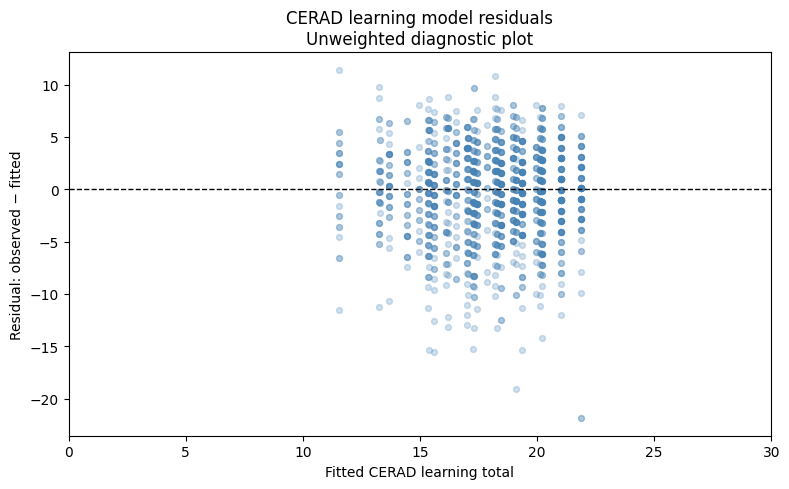

In [ ]:
# Plot CERAD learning residuals against fitted scores.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    learning_fitted,
    learning_y - learning_fitted,
    alpha=0.25,
    s=18,
    color="steelblue",
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlim(0, 30)
ax.set_xlabel("Fitted CERAD learning total")
ax.set_ylabel("Residual: observed − fitted")
ax.set_title(
    "CERAD learning model residuals\n"
    "Unweighted diagnostic plot"
)

plt.tight_layout()
plt.show()

In [ ]:
# Count observed predictor profiles and distinct fitted values.
predictor_profiles = learning_rows[
    ["age_model", "education_model", "sex_model"]
].drop_duplicates()

profile_check = pd.DataFrame({
    "check": [
        "Participants in the model",
        "Observed combinations of predictors",
        "Distinct fitted values, rounded to 6 decimals",
    ],
    "value": [
        len(learning_rows),
        len(predictor_profiles),
        len(np.unique(np.round(learning_fitted, 6))),
    ],
})

display(profile_check)

,check,value
0,Participants in the model,1455
1,Observed combinations of predictors,30
2,"Distinct fitted values, rounded to 6 decimals",30


### Animal Fluency model


In [ ]:
# Fit the survey-weighted Animal Fluency model.
model_frame["in_fluency_analysis"] = (
    valid_predictors
    & model_frame["CFDAST"].notna()
)

fluency_model_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "CFDAST",
    "age_model",
    "education_model",
    "sex_model",
    "in_fluency_analysis",
]

fluency_model_data = pl.from_pandas(
    model_frame[fluency_model_columns]
)

fluency_model_sample = svy.Sample(
    data=fluency_model_data,
    design=survey_design,
)

fluency_model = fluency_model_sample.glm.fit(
    y="CFDAST",
    x=[
        svy.Cat("age_model", ref="60–69"),
        svy.Cat("education_model", ref="Less than 9th grade"),
        svy.Cat("sex_model", ref="Female"),
    ],
    family="gaussian",
    where=svy.col("in_fluency_analysis") == True,
)

print(fluency_model)

╭───────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: CFDAST                                                                                                   │
│ where: in_fluency_analysis == true                                                                                 │
│                                                                                                                    │
│ Observations        1447  AIC           8849.8486                                                                  │
│ DF Residuals          10  BIC                   -                                                                  │
│ Deviance      37676.0860  Scale           26.1821                                                                  │
│ R-squared        0.25476  R-sq (adj)      0.25113                                                                  │
│                           Iterations            2                                                                  │
│ F-stat (adj)    20.42709  Prob (F-adj)     0.0056                                                                  │
│                                                                                                                    │
│                                                                                                                    │
│  Term                                                 Coef.   Std.Err.           t    P>|t|     [0.025     0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                       15.79273    0.59920    26.35638   <0.001   14.45763   17.12783  │
│  age_model_70–79                                   -2.67393    0.39553    -6.76034   <0.001   -3.55523   -1.79263  │
│  age_model_80+                                     -4.26675    0.38513   -11.07860   <0.001   -5.12488   -3.40861  │
│  education_model_9th–11th grade                     0.70504    0.66683     1.05730   0.3152   -0.78075    2.19084  │
│  education_model_College graduate or higher         6.28492    0.63097     9.96074   <0.001    4.87904    7.69081  │
│  education_model_High school graduate / GED         2.03724    0.65830     3.09472   0.0114    0.57046    3.50401  │
│  education_model_Some college / associate degree    4.03163    0.60606     6.65219   <0.001    2.68124    5.38202  │
│  sex_model_Male                                     0.09268    0.42726     0.21691   0.8326   -0.85931    1.04466  │
│                                                                                                                    │
╰────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
# Independently check the Animal Fluency model coefficients.
fluency_rows = model_frame.loc[
    model_frame["in_fluency_analysis"]
].copy()

fluency_X = pd.DataFrame(index=fluency_rows.index)
fluency_X["_intercept_"] = 1.0

fluency_terms = {
    "age_model_70–79": ("age_model", "70–79"),
    "age_model_80+": ("age_model", "80+"),
    "education_model_9th–11th grade": (
        "education_model", "9th–11th grade"
    ),
    "education_model_College graduate or higher": (
        "education_model", "College graduate or higher"
    ),
    "education_model_High school graduate / GED": (
        "education_model", "High school graduate / GED"
    ),
    "education_model_Some college / associate degree": (
        "education_model", "Some college / associate degree"
    ),
    "sex_model_Male": ("sex_model", "Male"),
}

for term, (column, category) in fluency_terms.items():
    fluency_X[term] = (fluency_rows[column] == category).astype(float)

fluency_X_array = fluency_X.to_numpy(dtype=float)
fluency_y = fluency_rows["CFDAST"].to_numpy(dtype=float)
fluency_weights = fluency_rows["WTMEC2YR"].to_numpy(dtype=float)

fluency_sqrt_weights = np.sqrt(fluency_weights)

fluency_manual_coefficients = np.linalg.lstsq(
    fluency_X_array * fluency_sqrt_weights[:, None],
    fluency_y * fluency_sqrt_weights,
    rcond=None,
)[0]

fluency_manual_results = pd.DataFrame({
    "term": fluency_X.columns,
    "manual_coefficient": fluency_manual_coefficients,
})

fluency_svy_results = fluency_model.to_polars().to_pandas()[
    ["term", "estimate"]
]

fluency_coefficient_check = fluency_manual_results.merge(
    fluency_svy_results,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (fluency_coefficient_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

fluency_coefficient_check["difference"] = (
    fluency_coefficient_check["manual_coefficient"]
    - fluency_coefficient_check["estimate"]
)

print("Participants:", len(fluency_rows))
print("Strata:", fluency_rows["SDMVSTRA"].nunique())
print(
    "Sampling units:",
    len(fluency_rows[["SDMVSTRA", "SDMVPSU"]].drop_duplicates())
)

display(
    fluency_coefficient_check[
        ["term", "manual_coefficient", "estimate", "difference"]
    ].round(6)
)

Participants: 1447
Strata: 14
Sampling units: 31


,term,manual_coefficient,estimate,difference
0,_intercept_,15.792733,15.792733,0.0
1,age_model_70–79,-2.673932,-2.673932,-0.0
2,age_model_80+,-4.266746,-4.266746,-0.0
3,education_model_9th–11th grade,0.705045,0.705045,-0.0
4,education_model_College graduate or higher,6.284924,6.284924,-0.0
5,education_model_High school graduate / GED,2.037236,2.037236,-0.0
6,education_model_Some college / associate degree,4.031632,4.031632,-0.0
7,sex_model_Male,0.092677,0.092677,-0.0


In [ ]:
# Independently check standard errors and intervals for Animal Fluency.
fluency_residuals = (
    fluency_y - fluency_X_array @ fluency_manual_coefficients
)

fluency_score_columns = list(fluency_X.columns)

# Start with zero contributions for every MEC participant.
fluency_scores = pd.DataFrame(
    0.0,
    index=model_frame.index,
    columns=fluency_score_columns,
)

fluency_scores.loc[fluency_rows.index, fluency_score_columns] = (
    fluency_X_array
    * (fluency_weights * fluency_residuals)[:, None]
)

fluency_scores = model_frame[["SDMVSTRA", "SDMVPSU"]].join(
    fluency_scores
)

fluency_psu_scores = (
    fluency_scores
    .groupby(["SDMVSTRA", "SDMVPSU"])[fluency_score_columns]
    .sum()
)

fluency_meat = np.zeros(
    (len(fluency_score_columns), len(fluency_score_columns))
)

for _, stratum in fluency_psu_scores.groupby(level="SDMVSTRA"):
    psu_values = stratum.to_numpy()
    number_of_psus = len(psu_values)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    centered = psu_values - psu_values.mean(axis=0)

    fluency_meat += (
        number_of_psus / (number_of_psus - 1)
        * centered.T @ centered
    )

fluency_bread = (
    fluency_X_array.T
    @ (fluency_weights[:, None] * fluency_X_array)
)

fluency_bread_inverse = np.linalg.inv(fluency_bread)

fluency_covariance = (
    fluency_bread_inverse
    @ fluency_meat
    @ fluency_bread_inverse.T
)

fluency_manual_se = np.sqrt(np.diag(fluency_covariance))

# Use the same residual degrees-of-freedom convention as before.
fluency_design_df = (
    len(fluency_rows[["SDMVSTRA", "SDMVPSU"]].drop_duplicates())
    - fluency_rows["SDMVSTRA"].nunique()
)

fluency_model_df = (
    fluency_design_df - (len(fluency_score_columns) - 1)
)

fluency_critical_value = t.ppf(0.975, df=fluency_model_df)

fluency_manual_check = pd.DataFrame({
    "term": fluency_score_columns,
    "manual_se": fluency_manual_se,
    "manual_lower": (
        fluency_manual_coefficients
        - fluency_critical_value * fluency_manual_se
    ),
    "manual_upper": (
        fluency_manual_coefficients
        + fluency_critical_value * fluency_manual_se
    ),
})

fluency_svy_check = fluency_model.to_polars().to_pandas()[
    ["term", "std_err", "conf_low", "conf_high", "df"]
]

fluency_uncertainty_check = fluency_manual_check.merge(
    fluency_svy_check,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (fluency_uncertainty_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

fluency_uncertainty_check["se_difference"] = (
    fluency_uncertainty_check["manual_se"]
    - fluency_uncertainty_check["std_err"]
)

fluency_uncertainty_check["lower_difference"] = (
    fluency_uncertainty_check["manual_lower"]
    - fluency_uncertainty_check["conf_low"]
)

fluency_uncertainty_check["upper_difference"] = (
    fluency_uncertainty_check["manual_upper"]
    - fluency_uncertainty_check["conf_high"]
)

print("Design degrees of freedom:", fluency_design_df)
print("Manual model degrees of freedom:", fluency_model_df)

display(
    fluency_uncertainty_check[
        [
            "term",
            "df",
            "std_err",
            "se_difference",
            "lower_difference",
            "upper_difference",
        ]
    ].round(6)
)

Design degrees of freedom: 17
Manual model degrees of freedom: 10


,term,df,std_err,se_difference,lower_difference,upper_difference
0,_intercept_,10,0.599200,0.0,0.0,0.0
1,age_model_70–79,10,0.395532,0.0,-0.0,-0.0
2,age_model_80+,10,0.385134,-0.0,-0.0,-0.0
3,education_model_9th–11th grade,10,0.666834,0.0,-0.0,-0.0
4,education_model_College graduate or higher,10,0.630970,0.0,-0.0,-0.0
5,education_model_High school graduate / GED,10,0.658295,0.0,-0.0,-0.0
6,education_model_Some college / associate degree,10,0.606061,0.0,-0.0,-0.0
7,sex_model_Male,10,0.427257,-0.0,-0.0,-0.0


#### Animal Fluency diagnostics


In [ ]:
# Check fitted values for the Animal Fluency model.
fluency_fitted = fluency_X_array @ fluency_manual_coefficients

fluency_prediction_check = pd.DataFrame({
    "check": [
        "Participants in the model",
        "Lowest fitted value",
        "Highest fitted value",
        "Fitted values below 0",
    ],
    "value": [
        len(fluency_fitted),
        fluency_fitted.min(),
        fluency_fitted.max(),
        int((fluency_fitted < 0).sum()),
    ],
})

display(fluency_prediction_check.round(3))

,check,value
0,Participants in the model,1447.000
1,Lowest fitted value,11.526
2,Highest fitted value,22.170
3,Fitted values below 0,0.000


In [ ]:
# Describe Animal Fluency model residuals by age group.
fluency_diagnostics = fluency_rows.assign(
    residual=fluency_y - fluency_fitted
)

fluency_residuals_by_age = (
    fluency_diagnostics
    .groupby("age_model", observed=True)
    .agg(
        participants=("residual", "size"),
        residual_std=("residual", "std"),
        residual_10th_percentile=(
            "residual", lambda values: values.quantile(0.10)
        ),
        residual_90th_percentile=(
            "residual", lambda values: values.quantile(0.90)
        ),
    )
    .round(2)
)

display(fluency_residuals_by_age)

,participants,residual_std,residual_10th_percentile,residual_90th_percentile
age_model,,,,
60–69,781,5.25,-8.08,5.08
70–79,423,5.10,-6.40,5.84
80+,243,4.53,-5.65,5.23


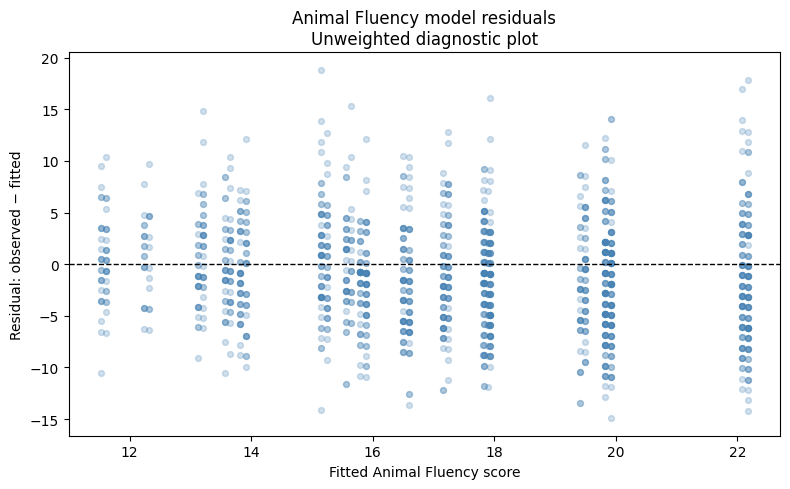

In [ ]:
# Plot Animal Fluency residuals against fitted scores.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    fluency_fitted,
    fluency_residuals,
    alpha=0.25,
    s=18,
    color="steelblue",
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlabel("Fitted Animal Fluency score")
ax.set_ylabel("Residual: observed − fitted")
ax.set_title(
    "Animal Fluency model residuals\n"
    "Unweighted diagnostic plot"
)

plt.tight_layout()
plt.show()

### DSST model


In [ ]:
# Fit the survey-weighted DSST model.
model_frame["in_dsst_analysis"] = (
    valid_predictors
    & model_frame["CFDDS"].notna()
)

dsst_model_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "CFDDS",
    "age_model",
    "education_model",
    "sex_model",
    "in_dsst_analysis",
]

dsst_model_data = pl.from_pandas(
    model_frame[dsst_model_columns]
)

dsst_model_sample = svy.Sample(
    data=dsst_model_data,
    design=survey_design,
)

dsst_model = dsst_model_sample.glm.fit(
    y="CFDDS",
    x=[
        svy.Cat("age_model", ref="60–69"),
        svy.Cat("education_model", ref="Less than 9th grade"),
        svy.Cat("sex_model", ref="Female"),
    ],
    family="gaussian",
    where=svy.col("in_dsst_analysis") == True,
)

print(dsst_model)

╭────────────────────────────────────────────── GLM: Gaussian (identity) ──────────────────────────────────────────────╮
│ Modeling: CFDDS                                                                                                      │
│ where: in_dsst_analysis == true                                                                                      │
│                                                                                                                      │
│ Observations         1420  AIC           11390.4003                                                                  │
│ DF Residuals           10  BIC                    -                                                                  │
│ Deviance      249242.6205  Scale           176.5174                                                                  │
│ R-squared         0.41730  R-sq (adj)       0.41441                                                                  │
│                            Iterations             2                                                                  │
│ F-stat (adj)     31.82660  Prob (F-adj)      0.0024                                                                  │
│                                                                                                                      │
│                                                                                                                      │
│  Term                                                 Coef.   Std.Err.           t    P>|t|      [0.025      0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                       36.97194    1.68144    21.98830   <0.001    33.22546    40.71841  │
│  age_model_70–79                                   -7.29698    0.92578    -7.88197   <0.001    -9.35975    -5.23421  │
│  age_model_80+                                    -15.16013    1.28585   -11.79001   <0.001   -18.02518   -12.29509  │
│  education_model_9th–11th grade                     9.77084    1.57386     6.20820   <0.001     6.26406    13.27762  │
│  education_model_College graduate or higher        30.41855    1.98846    15.29758   <0.001    25.98799    34.84910  │
│  education_model_High school graduate / GED        18.62926    1.74522    10.67443   <0.001    14.74066    22.51786  │
│  education_model_Some college / associate          24.93109    2.08252    11.97162   <0.001    20.29096    29.57123  │
│  degree                                                                                                              │
│  sex_model_Male                                    -4.68537    0.63343    -7.39687   <0.001    -6.09673    -3.27400  │
│                                                                                                                      │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
# Independently check the DSST model coefficients.
dsst_rows = model_frame.loc[
    model_frame["in_dsst_analysis"]
].copy()

dsst_X = pd.DataFrame(index=dsst_rows.index)
dsst_X["_intercept_"] = 1.0

# Reuse the category definitions from the Animal Fluency check.
for term, (column, category) in fluency_terms.items():
    dsst_X[term] = (dsst_rows[column] == category).astype(float)

dsst_X_array = dsst_X.to_numpy(dtype=float)
dsst_y = dsst_rows["CFDDS"].to_numpy(dtype=float)
dsst_weights = dsst_rows["WTMEC2YR"].to_numpy(dtype=float)

dsst_sqrt_weights = np.sqrt(dsst_weights)

dsst_manual_coefficients = np.linalg.lstsq(
    dsst_X_array * dsst_sqrt_weights[:, None],
    dsst_y * dsst_sqrt_weights,
    rcond=None,
)[0]

dsst_manual_results = pd.DataFrame({
    "term": dsst_X.columns,
    "manual_coefficient": dsst_manual_coefficients,
})

dsst_svy_results = dsst_model.to_polars().to_pandas()[
    ["term", "estimate"]
]

dsst_coefficient_check = dsst_manual_results.merge(
    dsst_svy_results,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (dsst_coefficient_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

dsst_coefficient_check["difference"] = (
    dsst_coefficient_check["manual_coefficient"]
    - dsst_coefficient_check["estimate"]
)

print("Participants:", len(dsst_rows))
print("Strata:", dsst_rows["SDMVSTRA"].nunique())
print(
    "Sampling units:",
    len(dsst_rows[["SDMVSTRA", "SDMVPSU"]].drop_duplicates())
)

display(
    dsst_coefficient_check[
        ["term", "manual_coefficient", "estimate", "difference"]
    ].round(6)
)

Participants: 1420
Strata: 14
Sampling units: 31


,term,manual_coefficient,estimate,difference
0,_intercept_,36.971937,36.971937,-0.0
1,age_model_70–79,-7.296982,-7.296982,0.0
2,age_model_80+,-15.160133,-15.160133,-0.0
3,education_model_9th–11th grade,9.770841,9.770841,0.0
4,education_model_College graduate or higher,30.418547,30.418547,0.0
5,education_model_High school graduate / GED,18.629261,18.629261,-0.0
6,education_model_Some college / associate degree,24.931094,24.931094,0.0
7,sex_model_Male,-4.685366,-4.685366,0.0


In [ ]:
# Independently check DSST standard errors and confidence intervals.
dsst_residuals = dsst_y - dsst_X_array @ dsst_manual_coefficients
dsst_score_columns = list(dsst_X.columns)

# Start with zero contributions for every MEC participant.
dsst_scores = pd.DataFrame(
    0.0,
    index=model_frame.index,
    columns=dsst_score_columns,
)

dsst_scores.loc[dsst_rows.index, dsst_score_columns] = (
    dsst_X_array * (dsst_weights * dsst_residuals)[:, None]
)

dsst_scores = model_frame[["SDMVSTRA", "SDMVPSU"]].join(
    dsst_scores
)

dsst_psu_scores = (
    dsst_scores
    .groupby(["SDMVSTRA", "SDMVPSU"])[dsst_score_columns]
    .sum()
)

dsst_meat = np.zeros(
    (len(dsst_score_columns), len(dsst_score_columns))
)

for _, stratum in dsst_psu_scores.groupby(level="SDMVSTRA"):
    psu_values = stratum.to_numpy()
    number_of_psus = len(psu_values)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    centered = psu_values - psu_values.mean(axis=0)

    dsst_meat += (
        number_of_psus / (number_of_psus - 1)
        * centered.T @ centered
    )

dsst_bread = (
    dsst_X_array.T
    @ (dsst_weights[:, None] * dsst_X_array)
)

dsst_bread_inverse = np.linalg.inv(dsst_bread)

dsst_covariance = (
    dsst_bread_inverse
    @ dsst_meat
    @ dsst_bread_inverse.T
)

dsst_manual_se = np.sqrt(np.diag(dsst_covariance))

# Apply the same degrees-of-freedom convention used before.
dsst_design_df = (
    len(dsst_rows[["SDMVSTRA", "SDMVPSU"]].drop_duplicates())
    - dsst_rows["SDMVSTRA"].nunique()
)

dsst_model_df = dsst_design_df - (len(dsst_score_columns) - 1)
dsst_critical_value = t.ppf(0.975, df=dsst_model_df)

dsst_manual_check = pd.DataFrame({
    "term": dsst_score_columns,
    "manual_se": dsst_manual_se,
    "manual_lower": (
        dsst_manual_coefficients
        - dsst_critical_value * dsst_manual_se
    ),
    "manual_upper": (
        dsst_manual_coefficients
        + dsst_critical_value * dsst_manual_se
    ),
})

dsst_svy_check = dsst_model.to_polars().to_pandas()[
    ["term", "std_err", "conf_low", "conf_high", "df"]
]

dsst_uncertainty_check = dsst_manual_check.merge(
    dsst_svy_check,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (dsst_uncertainty_check["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

dsst_uncertainty_check["se_difference"] = (
    dsst_uncertainty_check["manual_se"]
    - dsst_uncertainty_check["std_err"]
)

dsst_uncertainty_check["lower_difference"] = (
    dsst_uncertainty_check["manual_lower"]
    - dsst_uncertainty_check["conf_low"]
)

dsst_uncertainty_check["upper_difference"] = (
    dsst_uncertainty_check["manual_upper"]
    - dsst_uncertainty_check["conf_high"]
)

print("Design degrees of freedom:", dsst_design_df)
print("Manual model degrees of freedom:", dsst_model_df)

display(
    dsst_uncertainty_check[
        [
            "term",
            "df",
            "std_err",
            "se_difference",
            "lower_difference",
            "upper_difference",
        ]
    ].round(6)
)

Design degrees of freedom: 17
Manual model degrees of freedom: 10


,term,df,std_err,se_difference,lower_difference,upper_difference
0,_intercept_,10,1.681437,0.0,-0.0,0.0
1,age_model_70–79,10,0.925781,-0.0,0.0,0.0
2,age_model_80+,10,1.285846,0.0,-0.0,-0.0
3,education_model_9th–11th grade,10,1.573860,0.0,-0.0,0.0
4,education_model_College graduate or higher,10,1.988455,0.0,0.0,0.0
5,education_model_High school graduate / GED,10,1.745223,0.0,-0.0,0.0
6,education_model_Some college / associate degree,10,2.082516,0.0,-0.0,0.0
7,sex_model_Male,10,0.633426,0.0,-0.0,0.0


#### DSST diagnostics


In [ ]:
# Check fitted values for the DSST model.
dsst_fitted = dsst_X_array @ dsst_manual_coefficients

dsst_prediction_check = pd.DataFrame({
    "check": [
        "Participants in the model",
        "Lowest fitted value",
        "Highest fitted value",
        "Fitted values below 0",
        "Fitted values above 133",
    ],
    "value": [
        len(dsst_fitted),
        dsst_fitted.min(),
        dsst_fitted.max(),
        int((dsst_fitted < 0).sum()),
        int((dsst_fitted > 133).sum()),
    ],
})

display(dsst_prediction_check.round(3))

,check,value
0,Participants in the model,1420.000
1,Lowest fitted value,17.126
2,Highest fitted value,67.390
3,Fitted values below 0,0.000
4,Fitted values above 133,0.000


In [ ]:
# Describe DSST model residuals by age group.
dsst_diagnostics = dsst_rows.assign(
    residual=dsst_y - dsst_fitted
)

dsst_residuals_by_age = (
    dsst_diagnostics
    .groupby("age_model", observed=True)
    .agg(
        participants=("residual", "size"),
        residual_std=("residual", "std"),
        residual_10th_percentile=(
            "residual", lambda values: values.quantile(0.10)
        ),
        residual_90th_percentile=(
            "residual", lambda values: values.quantile(0.90)
        ),
    )
    .round(2)
)

display(dsst_residuals_by_age)

,participants,residual_std,residual_10th_percentile,residual_90th_percentile
age_model,,,,
60–69,782,13.96,-23.90,12.37
70–79,413,13.69,-21.73,12.94
80+,225,13.33,-18.04,16.04


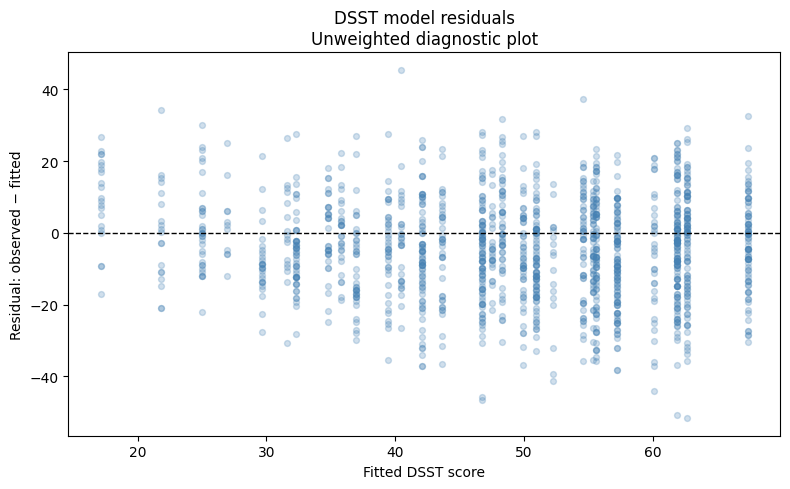

In [ ]:
# Plot DSST model residuals against fitted scores.
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    dsst_fitted,
    dsst_residuals,
    alpha=0.25,
    s=18,
    color="steelblue",
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlabel("Fitted DSST score")
ax.set_ylabel("Residual: observed − fitted")
ax.set_title(
    "DSST model residuals\n"
    "Unweighted diagnostic plot"
)

plt.tight_layout()
plt.show()

## 12. Weighted descriptions and missingness
Weighted and unweighted summaries use the populations identified in each cell. MEC weights do not automatically correct missing cognitive test data.


In [ ]:
# Compare unweighted and weighted delayed recall means
# in the same primary-analysis group.
unweighted_primary_mean = primary_check["CFDCSR"].mean()

weighted_primary_mean = (
    (primary_check["CFDCSR"] * primary_check["WTMEC2YR"]).sum()
    / primary_check["WTMEC2YR"].sum()
)

mean_comparison = pd.DataFrame({
    "measure": [
        "Unweighted mean",
        "Weighted mean",
        "Weighted minus unweighted",
    ],
    "value": [
        unweighted_primary_mean,
        weighted_primary_mean,
        weighted_primary_mean - unweighted_primary_mean,
    ],
})

print("Participants in both calculations:", len(primary_check))
display(mean_comparison.round(4))

Participants in both calculations: 1452


,measure,value
0,Unweighted mean,5.4146
1,Weighted mean,5.7629
2,Weighted minus unweighted,0.3483


In [ ]:
# Compare weighted and unweighted means by age group.
primary_by_age = primary_check.copy()

primary_by_age["age_group"] = pd.cut(
    primary_by_age["RIDAGEYR"],
    bins=[60, 70, 80, 81],
    labels=["60–69", "70–79", "80+"],
    right=False,
)

primary_by_age["weighted_score"] = (
    primary_by_age["CFDCSR"] * primary_by_age["WTMEC2YR"]
)

age_mean_comparison = (
    primary_by_age
    .groupby("age_group", observed=True)
    .agg(
        participants=("CFDCSR", "size"),
        unweighted_mean=("CFDCSR", "mean"),
        weighted_score_sum=("weighted_score", "sum"),
        weight_sum=("WTMEC2YR", "sum"),
    )
)

age_mean_comparison["weighted_mean"] = (
    age_mean_comparison["weighted_score_sum"]
    / age_mean_comparison["weight_sum"]
)

age_mean_comparison["weighted_minus_unweighted"] = (
    age_mean_comparison["weighted_mean"]
    - age_mean_comparison["unweighted_mean"]
)

display(
    age_mean_comparison[
        [
            "participants",
            "unweighted_mean",
            "weighted_mean",
            "weighted_minus_unweighted",
        ]
    ].round(4)
)

,participants,unweighted_mean,weighted_mean,weighted_minus_unweighted
age_group,,,,
60–69,780,6.0513,6.4524,0.4011
70–79,429,5.1002,5.3195,0.2193
80+,243,3.9259,4.1234,0.1975


In [ ]:
# Estimate weighted delayed recall means by age group.
weighted_recall_by_age = model_sample.estimation.mean(
    y="CFDCSR",
    by="age_model",
    where=svy.col("in_primary_analysis") == True,
)

print(weighted_recall_by_age)

╭──────────────── Estimate: MEAN (TAYLOR) ─────────────────╮
│ y: CFDCSR                                                │
│ where: in_primary_analysis == true                       │
│                                                          │
│  age_model      est       se      lci      uci   cv (%)  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  60–69       6.4524   0.1814   6.0698   6.8351     2.81  │
│  70–79       5.3195   0.0850   5.1402   5.4988     1.60  │
│  80+         4.1234   0.2068   3.6850   4.5618     5.02  │
│                                                          │
╰──────────────────────────────────────────────────────────╯

In [ ]:
# Independently check weighted means and intervals by age group.
age_conditions = {
    "60–69": mec_design["RIDAGEYR"].between(60, 69),
    "70–79": mec_design["RIDAGEYR"].between(70, 79),
    "80+": mec_design["RIDAGEYR"] >= 80,
}

age_manual_results = []

for age_label, age_condition in age_conditions.items():
    domain = mec_design["in_primary_analysis"] & age_condition
    domain_data = mec_design.loc[domain]

    weight_sum = domain_data["WTMEC2YR"].sum()

    mean = (
        (domain_data["CFDCSR"] * domain_data["WTMEC2YR"]).sum()
        / weight_sum
    )

    # Keep all MEC sampling units, with zero contribution outside the domain.
    contributions = mec_design[["SDMVSTRA", "SDMVPSU"]].copy()
    contributions["linearized_value"] = 0.0

    contributions.loc[domain, "linearized_value"] = (
        domain_data["WTMEC2YR"]
        * (domain_data["CFDCSR"] - mean)
        / weight_sum
    )

    psu_totals = (
        contributions
        .groupby(["SDMVSTRA", "SDMVPSU"])["linearized_value"]
        .sum()
        .reset_index()
    )

    variance = 0.0

    for _, stratum in psu_totals.groupby("SDMVSTRA"):
        values = stratum["linearized_value"]
        number_of_psus = len(values)

        assert number_of_psus > 1, "A stratum has only one sampling unit."

        variance += (
            number_of_psus / (number_of_psus - 1)
            * ((values - values.mean()) ** 2).sum()
        )

    standard_error = variance ** 0.5

    # Count the sampling units and strata represented in this age group.
    active_psus = len(
        domain_data[["SDMVSTRA", "SDMVPSU"]].drop_duplicates()
    )
    active_strata = domain_data["SDMVSTRA"].nunique()
    domain_df = active_psus - active_strata

    critical = t.ppf(0.975, df=domain_df)

    age_manual_results.append({
        "age_group": age_label,
        "participants": len(domain_data),
        "active_psus": active_psus,
        "active_strata": active_strata,
        "df": domain_df,
        "mean": mean,
        "standard_error": standard_error,
        "lower_95": mean - critical * standard_error,
        "upper_95": mean + critical * standard_error,
    })

age_manual_check = pd.DataFrame(age_manual_results)

display(age_manual_check.round(4))

,age_group,participants,active_psus,active_strata,df,mean,standard_error,lower_95,upper_95
0,60–69,780,31,14,17,6.4524,0.1814,6.0698,6.8351
1,70–79,429,31,14,17,5.3195,0.0850,5.1402,5.4988
2,80+,243,30,14,16,4.1234,0.2068,3.6850,4.5618


### Delayed recall missingness among examined participants aged 60+


In [ ]:
# Estimate delayed recall missingness among MEC participants aged 60+.
missingness_frame = mec_design.copy()

missingness_frame["older_domain"] = (
    missingness_frame["RIDAGEYR"] >= 60
)

missingness_frame["recall_missing_flag"] = (
    missingness_frame["CFDCSR"].isna().astype(int)
)

missingness_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "older_domain",
    "recall_missing_flag",
]

missingness_sample = svy.Sample(
    data=pl.from_pandas(missingness_frame[missingness_columns]),
    design=survey_design,
)

weighted_missingness = missingness_sample.estimation.mean(
    y="recall_missing_flag",
    where=svy.col("older_domain") == True,
)

print(weighted_missingness)

# Check the weighted proportion independently.
older_missingness = missingness_frame.loc[
    missingness_frame["older_domain"]
]

manual_missing_proportion = (
    (
        older_missingness["recall_missing_flag"]
        * older_missingness["WTMEC2YR"]
    ).sum()
    / older_missingness["WTMEC2YR"].sum()
)

print(f"Manual weighted proportion: {manual_missing_proportion:.4f}")
print(f"Observed participants aged 60+: {len(older_missingness)}")

╭────────── Estimate: MEAN (TAYLOR) ───────────╮
│ y: recall_missing_flag                       │
│ where: older_domain == true                  │
│                                              │
│     est       se      lci      uci   cv (%)  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  0.0981   0.0133   0.0699   0.1262    13.60  │
│                                              │
╰──────────────────────────────────────────────╯


Manual weighted proportion: 0.0981
Observed participants aged 60+: 1687


In [ ]:
# Independently check the weighted missingness estimate.
missingness_domain = missingness_frame["older_domain"]
older_weights = missingness_frame.loc[
    missingness_domain, "WTMEC2YR"
]

weight_sum = older_weights.sum()

missingness_taylor = missingness_frame[
    ["SDMVSTRA", "SDMVPSU"]
].copy()

# Keep all MEC participants; those outside the domain contribute zero.
missingness_taylor["linearized_value"] = 0.0

missingness_taylor.loc[missingness_domain, "linearized_value"] = (
    older_weights
    * (
        missingness_frame.loc[
            missingness_domain, "recall_missing_flag"
        ]
        - manual_missing_proportion
    )
    / weight_sum
)

missingness_psu = (
    missingness_taylor
    .groupby(["SDMVSTRA", "SDMVPSU"])["linearized_value"]
    .sum()
    .reset_index()
)

missingness_variance = 0.0

for _, stratum in missingness_psu.groupby("SDMVSTRA"):
    values = stratum["linearized_value"]
    number_of_psus = len(values)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    missingness_variance += (
        number_of_psus / (number_of_psus - 1)
        * ((values - values.mean()) ** 2).sum()
    )

manual_missing_se = missingness_variance ** 0.5

active_psus = len(
    older_missingness[["SDMVSTRA", "SDMVPSU"]].drop_duplicates()
)
active_strata = older_missingness["SDMVSTRA"].nunique()
missingness_df = active_psus - active_strata

critical = t.ppf(0.975, df=missingness_df)

manual_missing_lower = (
    manual_missing_proportion - critical * manual_missing_se
)
manual_missing_upper = (
    manual_missing_proportion + critical * manual_missing_se
)

print(f"Manual weighted proportion: {manual_missing_proportion:.4f}")
print(f"Manual standard error: {manual_missing_se:.4f}")
print(f"Degrees of freedom: {missingness_df}")
print(
    f"Manual 95% confidence interval: "
    f"[{manual_missing_lower:.4f}, {manual_missing_upper:.4f}]"
)

Manual weighted proportion: 0.0981
Manual standard error: 0.0133
Degrees of freedom: 17
Manual 95% confidence interval: [0.0699, 0.1262]


In [ ]:
# Estimate weighted delayed recall missingness by age group.
missingness_frame["age_group"] = pd.cut(
    missingness_frame["RIDAGEYR"],
    bins=[60, 70, 80, 81],
    labels=["60–69", "70–79", "80+"],
    right=False,
).astype("string")

missingness_age_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "older_domain",
    "age_group",
    "recall_missing_flag",
]

missingness_age_sample = svy.Sample(
    data=pl.from_pandas(missingness_frame[missingness_age_columns]),
    design=survey_design,
)

weighted_missingness_by_age = missingness_age_sample.estimation.mean(
    y="recall_missing_flag",
    by="age_group",
    where=svy.col("older_domain") == True,
)

print(weighted_missingness_by_age)

╭──────────────── Estimate: MEAN (TAYLOR) ─────────────────╮
│ y: recall_missing_flag                                   │
│ where: older_domain == true                              │
│                                                          │
│  age_group      est       se      lci      uci   cv (%)  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  60–69       0.0558   0.0151   0.0240   0.0876    27.02  │
│  70–79       0.0921   0.0170   0.0562   0.1281    18.47  │
│  80+         0.2322   0.0309   0.1671   0.2974    13.30  │
│                                                          │
╰──────────────────────────────────────────────────────────╯

In [ ]:
# Independently check weighted missingness estimates by age.
missingness_age_manual = []

for age_label in ["60–69", "70–79", "80+"]:
    domain = (
        missingness_frame["older_domain"]
        & missingness_frame["age_group"].eq(age_label).fillna(False)
    )

    domain_data = missingness_frame.loc[domain]
    weight_sum = domain_data["WTMEC2YR"].sum()

    proportion = (
        (
            domain_data["recall_missing_flag"]
            * domain_data["WTMEC2YR"]
        ).sum()
        / weight_sum
    )

    # Preserve all MEC sampling units for the variance calculation.
    contributions = missingness_frame[
        ["SDMVSTRA", "SDMVPSU"]
    ].copy()

    contributions["linearized_value"] = 0.0

    contributions.loc[domain, "linearized_value"] = (
        domain_data["WTMEC2YR"]
        * (domain_data["recall_missing_flag"] - proportion)
        / weight_sum
    )

    psu_totals = (
        contributions
        .groupby(["SDMVSTRA", "SDMVPSU"])["linearized_value"]
        .sum()
        .reset_index()
    )

    variance = 0.0

    for _, stratum in psu_totals.groupby("SDMVSTRA"):
        values = stratum["linearized_value"]
        number_of_psus = len(values)

        assert number_of_psus > 1, "A stratum has only one sampling unit."

        variance += (
            number_of_psus / (number_of_psus - 1)
            * ((values - values.mean()) ** 2).sum()
        )

    standard_error = variance ** 0.5

    active_psus = len(
        domain_data[["SDMVSTRA", "SDMVPSU"]].drop_duplicates()
    )
    active_strata = domain_data["SDMVSTRA"].nunique()
    domain_df = active_psus - active_strata

    critical = t.ppf(0.975, df=domain_df)

    missingness_age_manual.append({
        "age_group": age_label,
        "participants": len(domain_data),
        "active_psus": active_psus,
        "active_strata": active_strata,
        "df": domain_df,
        "proportion": proportion,
        "standard_error": standard_error,
        "lower_95": proportion - critical * standard_error,
        "upper_95": proportion + critical * standard_error,
    })

missingness_age_check = pd.DataFrame(missingness_age_manual)

display(missingness_age_check.round(4))

,age_group,participants,active_psus,active_strata,df,proportion,standard_error,lower_95,upper_95
0,60–69,868,31,14,17,0.0558,0.0151,0.0240,0.0876
1,70–79,493,31,14,17,0.0921,0.0170,0.0562,0.1281
2,80+,326,31,14,17,0.2322,0.0309,0.1671,0.2974


In [ ]:
# Estimate weighted delayed recall missingness by education.
missingness_frame["known_education"] = (
    missingness_frame["DMDEDUC2"].isin([1, 2, 3, 4, 5])
)

missingness_frame["education_group"] = (
    missingness_frame["DMDEDUC2"]
    .map(education_labels)
    .fillna("Not reported or unrecognized")
    .astype("string")
)

missingness_education_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "older_domain",
    "known_education",
    "education_group",
    "recall_missing_flag",
]

missingness_education_sample = svy.Sample(
    data=pl.from_pandas(
        missingness_frame[missingness_education_columns]
    ),
    design=survey_design,
)

weighted_missingness_by_education = (
    missingness_education_sample.estimation.mean(
        y="recall_missing_flag",
        by="education_group",
        where=(
            (svy.col("older_domain") == True)
            & (svy.col("known_education") == True)
        ),
    )
)

print(weighted_missingness_by_education)

print(
    "Observed participants with known education:",
    int(
        (
            missingness_frame["older_domain"]
            & missingness_frame["known_education"]
        ).sum()
    ),
)

╭─────────────────────────── Estimate: MEAN (TAYLOR) ────────────────────────────╮
│ y: recall_missing_flag                                                         │
│ where: ([older_domain == true]) & ([known_education == true])                  │
│                                                                                │
│  education_group                      est       se      lci      uci   cv (%)  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  9th–11th grade                    0.1247   0.0209   0.0806   0.1689    16.78  │
│  College graduate or higher        0.0470   0.0141   0.0171   0.0769    29.99  │
│  High school graduate / GED        0.1038   0.0228   0.0557   0.1520    22.00  │
│  Less than 9th grade               0.2905   0.0329   0.2209   0.3600    11.34  │
│  Some college / associate degree   0.0682   0.0211   0.0237   0.1126    30.92  │
│                                                                                │
╰────────────────────────────────────────────────────────────────────────────────╯


Observed participants with known education: 1683


In [ ]:
# Independently check weighted missingness by education.
education_manual_results = []

for education_code in [1, 2, 3, 4, 5]:
    domain = (
        missingness_frame["older_domain"]
        & missingness_frame["DMDEDUC2"].eq(education_code)
    )

    domain_data = missingness_frame.loc[domain]
    weight_sum = domain_data["WTMEC2YR"].sum()

    proportion = (
        (
            domain_data["recall_missing_flag"]
            * domain_data["WTMEC2YR"]
        ).sum()
        / weight_sum
    )

    # Preserve every MEC sampling unit for the variance calculation.
    contributions = missingness_frame[
        ["SDMVSTRA", "SDMVPSU"]
    ].copy()

    contributions["linearized_value"] = 0.0

    contributions.loc[domain, "linearized_value"] = (
        domain_data["WTMEC2YR"]
        * (domain_data["recall_missing_flag"] - proportion)
        / weight_sum
    )

    psu_totals = (
        contributions
        .groupby(["SDMVSTRA", "SDMVPSU"])["linearized_value"]
        .sum()
        .reset_index()
    )

    variance = 0.0

    for _, stratum in psu_totals.groupby("SDMVSTRA"):
        values = stratum["linearized_value"]
        number_of_psus = len(values)

        assert number_of_psus > 1, "A stratum has only one sampling unit."

        variance += (
            number_of_psus / (number_of_psus - 1)
            * ((values - values.mean()) ** 2).sum()
        )

    standard_error = variance ** 0.5

    active_psus = len(
        domain_data[["SDMVSTRA", "SDMVPSU"]].drop_duplicates()
    )
    active_strata = domain_data["SDMVSTRA"].nunique()
    domain_df = active_psus - active_strata

    critical = t.ppf(0.975, df=domain_df)

    education_manual_results.append({
        "education_group": education_labels[education_code],
        "participants": len(domain_data),
        "active_psus": active_psus,
        "active_strata": active_strata,
        "df": domain_df,
        "proportion": proportion,
        "standard_error": standard_error,
        "lower_95": proportion - critical * standard_error,
        "upper_95": proportion + critical * standard_error,
    })

education_manual_check = pd.DataFrame(education_manual_results)

display(education_manual_check.round(4))

,education_group,participants,active_psus,active_strata,df,proportion,standard_error,lower_95,upper_95
0,Less than 9th grade,285,31,14,17,0.2905,0.0329,0.2209,0.3600
1,9th–11th grade,257,31,14,17,0.1247,0.0209,0.0806,0.1689
2,High school graduate / GED,373,31,14,17,0.1038,0.0228,0.0557,0.1520
3,Some college / associate degree,431,31,14,17,0.0682,0.0211,0.0237,0.1126
4,College graduate or higher,337,30,14,16,0.0470,0.0141,0.0171,0.0769


## 13. Sensitivity analyses and interpretation
The following comparisons are exploratory. The first concerns two additional complete-case exclusions; it cannot quantify the effect of missing recall scores.


In [ ]:
# Compare weighted recall means under two inclusion rules.
recall_available = mec_design.loc[
    (mec_design["RIDAGEYR"] >= 60)
    & mec_design["CFDCSR"].notna()
]

complete_model_cases = mec_design.loc[
    mec_design["in_primary_analysis"]
]

sensitivity_results = []

for label, group in [
    ("Delayed recall available", recall_available),
    ("Complete cases for primary model", complete_model_cases),
]:
    weighted_mean = (
        (group["CFDCSR"] * group["WTMEC2YR"]).sum()
        / group["WTMEC2YR"].sum()
    )

    sensitivity_results.append({
        "inclusion_rule": label,
        "participants": len(group),
        "weighted_mean": weighted_mean,
    })

sensitivity_check = pd.DataFrame(sensitivity_results)

display(sensitivity_check.round(4))

,inclusion_rule,participants,weighted_mean
0,Delayed recall available,1454,5.7636
1,Complete cases for primary model,1452,5.7629


### Preliminary interpretation and limitations

In this sample, weighted model estimates show associations between age, education and delayed verbal recall after accounting for the other variables included in the model. These are observational associations and should not be interpreted as causal effects.

The weighted estimated proportion of missing delayed-recall scores was higher among participants aged 80 and over and among those in the lowest education category. Missingness included different circumstances, including ineligibility and assessments not performed. The MEC weights do not automatically remove possible bias from missing cognitive scores.

The weighted mean delayed-recall score was 5.7636 among the 1,454 participants with an available score and 5.7629 among the 1,452 complete cases used in the primary model. This comparison addresses the additional exclusion of two participants; it does not assess the effect of the 233 missing delayed-recall scores.

A CDC report using NHANES 2011–2014 also observed lower mean cognitive scores in older age groups and at lower education levels. The comparison is qualitative: the report combines two survey cycles and uses a different adjusted outcome and model.

**Reference:** Brody et al. (2019), [Cognitive Performance in Adults Aged 60 and Over: NHANES, 2011–2014](https://www.cdc.gov/nchs/data/nhsr/nhsr126-508.pdf).

### Common sample across all four cognitive outcomes


In [ ]:
# Check overlap between the four model samples.
model_domains = model_frame[
    [
        "in_primary_analysis",
        "in_learning_analysis",
        "in_fluency_analysis",
        "in_dsst_analysis",
    ]
]

sample_overlap = pd.DataFrame({
    "check": [
        "Delayed recall model",
        "CERAD learning model",
        "Animal Fluency model",
        "DSST model",
        "Included in all four models",
        "Included in at least one model",
    ],
    "participants": [
        int(model_domains["in_primary_analysis"].sum()),
        int(model_domains["in_learning_analysis"].sum()),
        int(model_domains["in_fluency_analysis"].sum()),
        int(model_domains["in_dsst_analysis"].sum()),
        int(model_domains.all(axis=1).sum()),
        int(model_domains.any(axis=1).sum()),
    ],
})

display(sample_overlap)

,check,participants
0,Delayed recall model,1452
1,CERAD learning model,1455
2,Animal Fluency model,1447
3,DSST model,1420
4,Included in all four models,1359
5,Included in at least one model,1498


In [ ]:
# Refit the primary model in the group included in all four models.
model_frame["in_all_four_models"] = model_domains.all(axis=1)

common_sample_columns = [
    "SDMVSTRA",
    "SDMVPSU",
    "WTMEC2YR",
    "CFDCSR",
    "age_model",
    "education_model",
    "sex_model",
    "in_all_four_models",
]

common_model_sample = svy.Sample(
    data=pl.from_pandas(model_frame[common_sample_columns]),
    design=survey_design,
)

common_primary_model = common_model_sample.glm.fit(
    y="CFDCSR",
    x=[
        svy.Cat("age_model", ref="60–69"),
        svy.Cat("education_model", ref="Less than 9th grade"),
        svy.Cat("sex_model", ref="Female"),
    ],
    family="gaussian",
    where=svy.col("in_all_four_models") == True,
)

print(common_primary_model)

╭──────────────────────────────────────────── GLM: Gaussian (identity) ─────────────────────────────────────────────╮
│ Modeling: CFDCSR                                                                                                  │
│ where: in_all_four_models == true                                                                                 │
│                                                                                                                   │
│ Observations       1359  AIC           5798.5874                                                                  │
│ DF Residuals         10  BIC                   -                                                                  │
│ Deviance      5531.8024  Scale            4.0946                                                                  │
│ R-squared       0.20091  R-sq (adj)      0.19677                                                                  │
│                          Iterations            2                                                                  │
│ F-stat (adj)   57.60612  Prob (F-adj)     <0.001                                                                  │
│                                                                                                                   │
│                                                                                                                   │
│  Term                                                 Coef.   Std.Err.          t    P>|t|     [0.025     0.975]  │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│  _intercept_                                        5.90064    0.37375   15.78758   <0.001    5.06787    6.73341  │
│  age_model_70–79                                   -0.97452    0.22830   -4.26853   0.0016   -1.48320   -0.46583  │
│  age_model_80+                                     -2.18944    0.30595   -7.15610   <0.001   -2.87114   -1.50773  │
│  education_model_9th–11th grade                     0.32501    0.28051    1.15864   0.2735   -0.30001    0.95003  │
│  education_model_College graduate or higher         1.28557    0.38476    3.34124   0.0075    0.42827    2.14286  │
│  education_model_High school graduate / GED         0.70089    0.27803    2.52086   0.0303    0.08139    1.32039  │
│  education_model_Some college / associate degree    1.23674    0.30968    3.99360   0.0025    0.54673    1.92675  │
│  sex_model_Male                                    -0.86865    0.10706   -8.11347   <0.001   -1.10720   -0.63010  │
│                                                                                                                   │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
# Compare the primary model with the common-sample model.
primary_results = (
    primary_model.to_polars().to_pandas()[
        ["term", "estimate", "conf_low", "conf_high"]
    ]
    .rename(columns={
        "estimate": "primary_estimate",
        "conf_low": "primary_lower",
        "conf_high": "primary_upper",
    })
)

common_results = (
    common_primary_model.to_polars().to_pandas()[
        ["term", "estimate", "conf_low", "conf_high"]
    ]
    .rename(columns={
        "estimate": "common_estimate",
        "conf_low": "common_lower",
        "conf_high": "common_upper",
    })
)

sample_model_comparison = primary_results.merge(
    common_results,
    on="term",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert (sample_model_comparison["_merge"] == "both").all(), (
    "The coefficient names do not match."
)

sample_model_comparison["change"] = (
    sample_model_comparison["common_estimate"]
    - sample_model_comparison["primary_estimate"]
)

# Focus on the comparisons rather than the intercept.
sample_model_comparison = sample_model_comparison.loc[
    sample_model_comparison["term"] != "_intercept_"
].copy()

display(
    sample_model_comparison[
        [
            "term",
            "primary_estimate",
            "primary_lower",
            "primary_upper",
            "common_estimate",
            "common_lower",
            "common_upper",
            "change",
        ]
    ].round(3)
)

,term,primary_estimate,primary_lower,primary_upper,common_estimate,common_lower,common_upper,change
1,age_model_70–79,-1.004,-1.487,-0.521,-0.975,-1.483,-0.466,0.030
2,age_model_80+,-2.200,-2.871,-1.529,-2.189,-2.871,-1.508,0.011
3,education_model_9th–11th grade,0.472,-0.057,1.001,0.325,-0.300,0.950,-0.147
4,education_model_College graduate or higher,1.416,0.624,2.208,1.286,0.428,2.143,-0.130
5,education_model_High school graduate / GED,0.884,0.263,1.505,0.701,0.081,1.320,-0.183
6,education_model_Some college / associate degree,1.398,0.785,2.011,1.237,0.547,1.927,-0.161
7,sex_model_Male,-0.870,-1.162,-0.578,-0.869,-1.107,-0.630,0.002


In [ ]:
# Independently check the common-sample model.
common_rows = model_frame.loc[
    model_frame["in_all_four_models"]
].copy()

common_X = pd.DataFrame(index=common_rows.index)
common_X["_intercept_"] = 1.0

for term, (column, category) in fluency_terms.items():
    common_X[term] = (common_rows[column] == category).astype(float)

common_X_array = common_X.to_numpy(dtype=float)
common_y = common_rows["CFDCSR"].to_numpy(dtype=float)
common_weights = common_rows["WTMEC2YR"].to_numpy(dtype=float)

# Independently calculate coefficients.
sqrt_common_weights = np.sqrt(common_weights)

common_manual_coefficients = np.linalg.lstsq(
    common_X_array * sqrt_common_weights[:, None],
    common_y * sqrt_common_weights,
    rcond=None,
)[0]

common_residuals = (
    common_y - common_X_array @ common_manual_coefficients
)

# Calculate sampling-unit contributions for the full MEC design.
common_scores = pd.DataFrame(
    0.0,
    index=model_frame.index,
    columns=common_X.columns,
)

common_scores.loc[common_rows.index, common_X.columns] = (
    common_X_array * (common_weights * common_residuals)[:, None]
)

common_scores = model_frame[["SDMVSTRA", "SDMVPSU"]].join(
    common_scores
)

common_psu_scores = (
    common_scores
    .groupby(["SDMVSTRA", "SDMVPSU"])[list(common_X.columns)]
    .sum()
)

common_meat = np.zeros((len(common_X.columns), len(common_X.columns)))

for _, stratum in common_psu_scores.groupby(level="SDMVSTRA"):
    psu_values = stratum.to_numpy()
    number_of_psus = len(psu_values)

    assert number_of_psus > 1, "A stratum has only one sampling unit."

    centered = psu_values - psu_values.mean(axis=0)

    common_meat += (
        number_of_psus / (number_of_psus - 1)
        * centered.T @ centered
    )

common_bread = (
    common_X_array.T @ (common_weights[:, None] * common_X_array)
)

common_bread_inverse = np.linalg.inv(common_bread)

common_covariance = (
    common_bread_inverse @ common_meat @ common_bread_inverse.T
)

common_manual_se = np.sqrt(np.diag(common_covariance))

# Calculate intervals using the same degrees-of-freedom convention.
common_psus = len(
    common_rows[["SDMVSTRA", "SDMVPSU"]].drop_duplicates()
)
common_strata = common_rows["SDMVSTRA"].nunique()
common_design_df = common_psus - common_strata
common_model_df = common_design_df - (len(common_X.columns) - 1)

common_critical = t.ppf(0.975, df=common_model_df)

common_manual_lower = (
    common_manual_coefficients - common_critical * common_manual_se
)
common_manual_upper = (
    common_manual_coefficients + common_critical * common_manual_se
)

# Compare with svy, matching each coefficient by name.
common_svy = (
    common_primary_model.to_polars().to_pandas()
    .set_index("term")
    .loc[common_X.columns]
)

print("Participants:", len(common_rows))
print("Strata:", common_strata)
print("Sampling units:", common_psus)
print("Model degrees of freedom:", common_model_df)

print(
    "Largest coefficient difference:",
    f"{np.max(np.abs(common_manual_coefficients - common_svy['estimate'].to_numpy())):.8f}"
)
print(
    "Largest standard error difference:",
    f"{np.max(np.abs(common_manual_se - common_svy['std_err'].to_numpy())):.8f}"
)
print(
    "Largest lower interval difference:",
    f"{np.max(np.abs(common_manual_lower - common_svy['conf_low'].to_numpy())):.8f}"
)
print(
    "Largest upper interval difference:",
    f"{np.max(np.abs(common_manual_upper - common_svy['conf_high'].to_numpy())):.8f}"
)

Participants: 1359
Strata: 14
Sampling units: 31
Model degrees of freedom: 10
Largest coefficient difference: 0.00000000
Largest standard error difference: 0.00000000
Largest lower interval difference: 0.00000000
Largest upper interval difference: 0.00000000


### Sensitivity analysis: common participant sample

The primary delayed-recall model included 1,452 participants. As a post hoc exploratory check, the same model was fitted to the 1,359 participants with complete data for all four cognitive outcomes.

The estimated associations retained their direction. For example, the estimated difference between participants aged 80 and over and those aged 60–69 changed from −2.200 to −2.189 points. Education coefficients changed by approximately −0.13 to −0.18 points across the categories shown.

Both models used the same reference categories and accounted for the NHANES survey design. Their samples overlap, so the comparison is descriptive and is not a formal test of differences between coefficients.

The common-sample analysis introduces additional completeness requirements. It does not correct potential bias caused by missing cognitive scores or establish causal effects.

## 14. Limitations


### Study limitations

- **Cross-sectional design.** The analysis compares different participants in NHANES 2011–2012. It does not measure cognitive change within the same person over time, and associations should not be interpreted as causal effects.
- **Missing cognitive scores.** The primary model includes complete cases. Score availability differed across age and education groups, and reasons included ineligibility and assessments not performed. MEC weights do not automatically correct for missing cognitive test scores.
- **Age and population coverage.** In the public data, age 80 represents participants aged 80 or older. NHANES targets the U.S. civilian non-institutionalized population; results should not be generalized without considering the survey design, exclusions and missing data.
- **Model specification.** The models include age group, education and recorded sex as additive categorical variables. Other relevant characteristics were not included. The linear models and unweighted residual plots are approximations that require cautious interpretation, particularly for scores with a limited range.
- **Uncertainty and multiple comparisons.** Intervals account for the survey design under the stated assumptions. Several outcomes and comparisons were examined; no multiple-comparison adjustment has been applied. Secondary and post hoc findings should therefore be interpreted as exploratory.
- **Clinical interpretation.** These tests measure performance in specific tasks. Individual scores and group differences do not provide diagnoses or, by themselves, establish the cause of a cognitive difficulty.
- **Sensitivity analysis.** Restricting the primary model to participants included in all four models produced estimates with the same direction, but this additional selection does not resolve possible missing-data bias.

In [ ]:
# Export aggregated results for the Power BI dashboard.
dashboard_dir = Path("dashboard_data")
dashboard_dir.mkdir(parents=True, exist_ok=True)

# 1. Weighted delayed-recall means by age.
dashboard_recall_age = age_manual_check[
    [
        "age_group",
        "participants",
        "mean",
        "lower_95",
        "upper_95",
        "df",
    ]
].rename(columns={
    "participants": "available_scores",
    "mean": "weighted_mean",
})

# 2. Weighted missing-score proportions by age.
dashboard_missing_age = missingness_age_check[
    [
        "age_group",
        "participants",
        "proportion",
        "lower_95",
        "upper_95",
        "df",
    ]
].copy()

for column in ["proportion", "lower_95", "upper_95"]:
    dashboard_missing_age[column] = (
        dashboard_missing_age[column] * 100
    )

dashboard_missing_age = dashboard_missing_age.rename(columns={
    "proportion": "missing_percentage",
    "lower_95": "lower_95_percentage",
    "upper_95": "upper_95_percentage",
})

# 3. Adjusted coefficients from the primary model.
dashboard_model = primary_model.to_polars().to_pandas()[
    ["term", "estimate", "conf_low", "conf_high", "df"]
].copy()

dashboard_model = dashboard_model.loc[
    dashboard_model["term"] != "_intercept_"
]

exports = {
    "weighted_recall_by_age.csv": dashboard_recall_age,
    "weighted_missingness_by_age.csv": dashboard_missing_age,
    "primary_model_coefficients.csv": dashboard_model,
}

for filename, table in exports.items():
    table.to_csv(
        dashboard_dir / filename,
        index=False,
        encoding="utf-8-sig",
    )
    print(f"{filename}: {len(table)} rows")

print(f"\nFiles saved in: {dashboard_dir.resolve()}")

weighted_recall_by_age.csv: 3 rows
weighted_missingness_by_age.csv: 3 rows
primary_model_coefficients.csv: 7 rows

Files saved in: /content/dashboard_data


In [ ]:
# Inspect the exported dashboard tables.
recall_export = pd.read_csv(
    dashboard_dir / "weighted_recall_by_age.csv",
    encoding="utf-8-sig",
)

missing_export = pd.read_csv(
    dashboard_dir / "weighted_missingness_by_age.csv",
    encoding="utf-8-sig",
)

model_export = pd.read_csv(
    dashboard_dir / "primary_model_coefficients.csv",
    encoding="utf-8-sig",
)

print("Weighted delayed recall by age:")
display(recall_export.round(3))

print("Weighted missingness by age:")
display(missing_export.round(3))

print("Primary model coefficients:")
display(model_export.round(3))

Weighted delayed recall by age:


,age_group,available_scores,weighted_mean,lower_95,upper_95,df
0,60–69,780,6.452,6.070,6.835,17
1,70–79,429,5.319,5.140,5.499,17
2,80+,243,4.123,3.685,4.562,16


Weighted missingness by age:


,age_group,participants,missing_percentage,lower_95_percentage,upper_95_percentage,df
0,60–69,868,5.581,2.399,8.762,17
1,70–79,493,9.215,5.624,12.806,17
2,80+,326,23.223,16.706,29.740,17


Primary model coefficients:


,term,estimate,conf_low,conf_high,df
0,age_model_70–79,-1.004,-1.487,-0.521,10
1,age_model_80+,-2.200,-2.871,-1.529,10
2,education_model_9th–11th grade,0.472,-0.057,1.001,10
3,education_model_College graduate or higher,1.416,0.624,2.208,10
4,education_model_High school graduate / GED,0.884,0.263,1.505,10
5,education_model_Some college / associate degree,1.398,0.785,2.011,10
6,sex_model_Male,-0.870,-1.162,-0.578,10
